In [1]:

import os
import sys
import random
import platform
import shutil
from pathlib import Path

import numpy as np
import torch

from google.colab import drive

# Connect Google Drive
drive.mount("/content/drive")

# Project configuration
PROJECT_NAME = "Video_Action_Recognition"

PROJECT_DIR = Path("/content/drive/MyDrive") / PROJECT_NAME
DATA_DIR = Path("/content/UCF101_subset")

# Create project folders
folders = [
    "configs",
    "data",
    "src/datasets",
    "src/models",
    "experiments",
    "checkpoints",
    "demo",
    "report",
    "contributions"
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

# Initial random seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device configuration
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 50)
print("HUMAN ACTION RECOGNITION PROJECT")
print("=" * 50)

print("Python Version:", sys.version.split()[0])
print("PyTorch Version:", torch.__version__)
print("Device:", DEVICE)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory (GB):",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3),
            2
        )
    )

free_space = shutil.disk_usage("/content").free / (1024 ** 3)

print("Free Disk Space (GB):", round(free_space, 2))
print("Project Folder:", PROJECT_DIR)

print("=" * 50)
print("SETUP COMPLETED")


Mounted at /content/drive
HUMAN ACTION RECOGNITION PROJECT
Python Version: 3.13.16
PyTorch Version: 2.14.1+cu130
Device: cuda
GPU Available: True
GPU Name: Tesla T4
GPU Memory (GB): 14.56
Free Disk Space (GB): 112.54
Project Folder: /content/drive/MyDrive/Video_Action_Recognition
SETUP COMPLETED


In [4]:

import re
import json
import tarfile
import pandas as pd
from pathlib import Path
from huggingface_hub import hf_hub_download

print("=" * 55)
print("CELL 2: DATASET DOWNLOAD & EXPLORATION")
print("=" * 55)

# 1. Download dataset
DATASET_REPO = "sayakpaul/ucf101-subset"

archive_path = hf_hub_download(
    repo_id=DATASET_REPO,
    filename="UCF101_subset.tar.gz",
    repo_type="dataset"
)

print("Dataset downloaded successfully!")

# 2. Extract videos
DATA_DIR = Path("/content/UCF101_subset")

if not DATA_DIR.exists() or not list(
    DATA_DIR.glob("*/*/*.avi")
):
    print("Extracting videos...")
    with tarfile.open(archive_path, "r:*") as tar:
        tar.extractall("/content", filter="data")

print("Extraction completed!")

# 3. Collect videos and labels
records = []

for split in ["train", "val", "test"]:
    for video_path in sorted(
        (DATA_DIR / split).glob("*/*.avi")
    ):
        group_match = re.search(
            r"_g(\d+)_c\d+", video_path.stem
        )

        group_id = (
            group_match.group(1)
            if group_match else None
        )

        records.append({
            "path": str(video_path),
            "split": split,
            "label": video_path.parent.name,
            "group_id": group_id
        })

df = pd.DataFrame(records)

assert not df.empty, "No videos found!"

# 4. Statistics
print("\nDATASET STATISTICS")
print("-" * 40)

print("Total Videos:", len(df))
print("Total Classes:", df["label"].nunique())

print("\nVideos per Split:")
print(df["split"].value_counts().to_string())

print("\nClass Distribution:")
print(
    pd.crosstab(df["label"], df["split"]).to_string()
)

# 5. Check group-level leakage
print("\nDATA LEAKAGE CHECK")

assert df["group_id"].notna().all(), (
    "Some video group IDs could not be parsed"
)

df["group_key"] = (
    df["label"] + "_g" + df["group_id"]
)

groups = {
    split: set(
        df.loc[
            df["split"] == split, "group_key"
        ]
    )
    for split in ["train", "val", "test"]
}

for a, b in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:
    overlap = groups[a] & groups[b]
    print(f"{a} vs {b}: {len(overlap)} overlaps")

    assert len(overlap) == 0, (
        f"Group leakage detected: {a} vs {b}"
    )

print("Group-level leakage check PASSED!")

# 6. Create label mapping
class_names = sorted(df["label"].unique())

label2id = {
    name: idx for idx, name in enumerate(class_names)
}

id2label = {
    idx: name for name, idx in label2id.items()
}

df["label_id"] = df["label"].map(label2id)

# 7. Save metadata
metadata_dir = PROJECT_DIR / "data"
metadata_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(
    metadata_dir / "dataset_metadata.csv",
    index=False
)

with open(
    metadata_dir / "labels.json", "w"
) as f:
    json.dump(label2id, f, indent=2)

print("\nClasses:")
for idx, name in enumerate(class_names):
    print(f"{idx}: {name}")

print("\nMetadata saved successfully!")
print("=" * 55)


CELL 2: DATASET DOWNLOAD & EXPLORATION
Dataset downloaded successfully!
Extraction completed!

DATASET STATISTICS
----------------------------------------
Total Videos: 405
Total Classes: 10

Videos per Split:
split
train    300
test      75
val       30

Class Distribution:
split           test  train  val
label                           
ApplyEyeMakeup     6     30    3
ApplyLipstick      4     30    3
Archery            7     30    3
BabyCrawling       9     30    3
BalanceBeam        4     30    3
BandMarching       9     30    3
BaseballPitch     10     30    3
Basketball        11     30    3
BasketballDunk     6     30    3
BenchPress         9     30    3

DATA LEAKAGE CHECK
train vs val: 0 overlaps
train vs test: 0 overlaps
val vs test: 0 overlaps
Group-level leakage check PASSED!

Classes:
0: ApplyEyeMakeup
1: ApplyLipstick
2: Archery
3: BabyCrawling
4: BalanceBeam
5: BandMarching
6: BaseballPitch
7: Basketball
8: BasketballDunk
9: BenchPress

Metadata saved successfully!


CELL 3: VIDEO PREPROCESSING
Sample Video: v_ApplyEyeMakeup_g02_c03.avi
True Action: ApplyEyeMakeup

Frames Shape: (16, 112, 112, 3)
Data Type: uint8
Pixel Range: 0 255


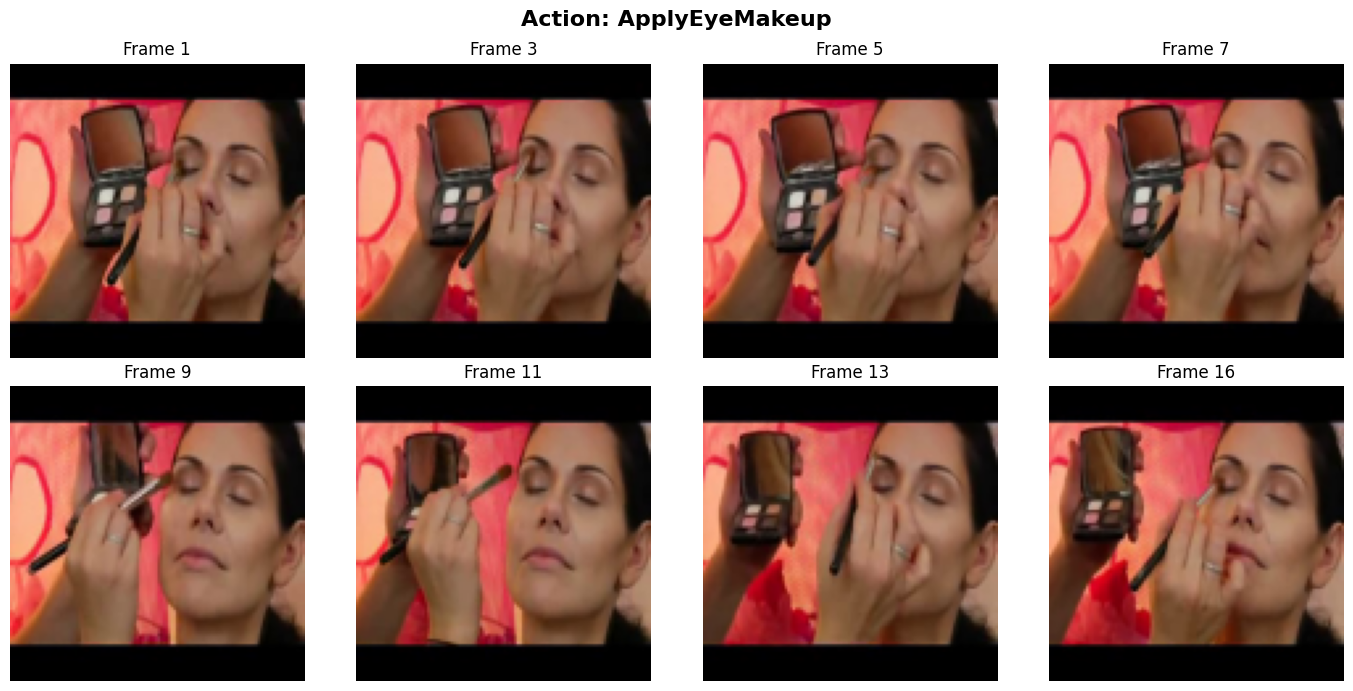

CELL 3 COMPLETED


In [5]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("=" * 55)
print("CELL 3: VIDEO PREPROCESSING")
print("=" * 55)

# Preprocessing configuration
NUM_FRAMES = 16
FRAME_SIZE = (112, 112)

# Custom video frame sampling function
def extract_frames(
    video_path,
    num_frames=NUM_FRAMES,
    frame_size=FRAME_SIZE
):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise ValueError(
            f"Cannot open video: {video_path}"
        )

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    if total_frames <= 0:
        cap.release()
        raise ValueError(
            f"Invalid video: {video_path}"
        )

    # Uniform temporal sampling
    indices = np.linspace(
        0,
        total_frames - 1,
        num_frames,
        dtype=int
    )

    frames = []
    last_frame = None

    for frame_idx in indices:
        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(frame_idx)
        )

        success, frame = cap.read()

        if success:
            # BGR -> RGB
            frame = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            # Resize
            frame = cv2.resize(
                frame,
                frame_size,
                interpolation=cv2.INTER_AREA
            )

            last_frame = frame

        elif last_frame is not None:
            frame = last_frame.copy()

        else:
            frame = np.zeros(
                (
                    frame_size[1],
                    frame_size[0],
                    3
                ),
                dtype=np.uint8
            )

        frames.append(frame)

    cap.release()

    return np.stack(frames, axis=0)


# Select one training video
sample_row = df[
    df["split"] == "train"
].iloc[0]

sample_path = sample_row["path"]
sample_label = sample_row["label"]

print("Sample Video:", Path(sample_path).name)
print("True Action:", sample_label)

# Extract frames
frames = extract_frames(sample_path)

print("\nFrames Shape:", frames.shape)
print("Data Type:", frames.dtype)
print("Pixel Range:", frames.min(), frames.max())

# Show 8 sampled frames
fig, axes = plt.subplots(
    2, 4,
    figsize=(14, 7)
)

selected_indices = np.linspace(
    0,
    NUM_FRAMES - 1,
    8,
    dtype=int
)

for ax, idx in zip(
    axes.flatten(),
    selected_indices
):
    ax.imshow(frames[idx])
    ax.set_title(f"Frame {idx + 1}")
    ax.axis("off")

plt.suptitle(
    f"Action: {sample_label}",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("=" * 55)
print("CELL 3 COMPLETED")


In [6]:

import os
import time
import shutil
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

print("=" * 55)
print("CELL 4: DATASET CACHING & PIPELINE")
print("=" * 55)

start_time = time.time()

# Keep consistent sample order
df = df.reset_index(drop=True)

N = len(df)
T = NUM_FRAMES
H, W = FRAME_SIZE[1], FRAME_SIZE[0]

assert N == 405, f"Unexpected dataset size: {N}"

# Cache paths
CACHE_NAME = "ucf101_16frames_112x112.npy"

LOCAL_CACHE = Path("/content") / CACHE_NAME
DRIVE_CACHE = PROJECT_DIR / "data" / CACHE_NAME

EXPECTED_SHAPE = (N, T, H, W, 3)

def cache_valid(path):
    if not path.exists():
        return False

    try:
        arr = np.load(path, mmap_mode="r")
        valid = (
            arr.shape == EXPECTED_SHAPE
            and arr.dtype == np.uint8
        )
        del arr
        return valid
    except Exception:
        return False


# Reuse existing cache
if cache_valid(LOCAL_CACHE):
    print("Using existing local cache.")

elif cache_valid(DRIVE_CACHE):
    print("Restoring cache from Google Drive...")
    shutil.copy2(DRIVE_CACHE, LOCAL_CACHE)

else:
    print("Preprocessing all videos...")

    temp_cache = LOCAL_CACHE.with_suffix(
        ".partial.npy"
    )

    if temp_cache.exists():
        temp_cache.unlink()

    X_cache = np.lib.format.open_memmap(
        temp_cache,
        mode="w+",
        dtype=np.uint8,
        shape=EXPECTED_SHAPE
    )

    for i, video_path in enumerate(
        tqdm(df["path"], total=N)
    ):
        X_cache[i] = extract_frames(
            video_path,
            num_frames=T,
            frame_size=FRAME_SIZE
        )

    X_cache.flush()
    del X_cache

    os.replace(temp_cache, LOCAL_CACHE)

    print("Preprocessing completed!")


# Save a persistent copy
if not cache_valid(DRIVE_CACHE):
    print("Saving cache to Google Drive...")
    shutil.copy2(LOCAL_CACHE, DRIVE_CACHE)

# Memory-mapped dataset
X = np.load(LOCAL_CACHE, mmap_mode="r")

# Labels
y = df["label_id"].to_numpy(
    dtype=np.int64
)

# Fixed split indices
split_indices = {
    split: np.flatnonzero(
        df["split"].to_numpy() == split
    )
    for split in ["train", "val", "test"]
}

train_idx = split_indices["train"]
val_idx = split_indices["val"]
test_idx = split_indices["test"]

# Check splits are separate
assert len(
    set(train_idx) & set(val_idx)
) == 0

assert len(
    set(train_idx) & set(test_idx)
) == 0

assert len(
    set(val_idx) & set(test_idx)
) == 0

assert len(train_idx) == 300
assert len(val_idx) == 30
assert len(test_idx) == 75

# Save sample order and splits
df.to_csv(
    PROJECT_DIR / "data" / "cached_sample_order.csv",
    index=False
)

for split, indices in split_indices.items():
    np.save(
        PROJECT_DIR / "data" / f"{split}_indices.npy",
        indices
    )

# Dataset checks
print("\nDATASET SHAPE:", X.shape)
print("LABELS SHAPE:", y.shape)
print("DATA TYPE:", X.dtype)

print("\nDATA SPLITS")
print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

print("\nExample Video Shape:", X[0].shape)
print("Example Label:", class_names[y[0]])

elapsed = time.time() - start_time

print("\nProcessing Time:", round(elapsed, 2), "seconds")
print("Cache Size (MB):", round(
    LOCAL_CACHE.stat().st_size / 1024**2, 2
))

print("Cache Saved To:", DRIVE_CACHE)

print("=" * 55)
print("CELL 4 COMPLETED")


CELL 4: DATASET CACHING & PIPELINE
Preprocessing all videos...


  0%|          | 0/405 [00:00<?, ?it/s]

Preprocessing completed!
Saving cache to Google Drive...

DATASET SHAPE: (405, 16, 112, 112, 3)
LABELS SHAPE: (405,)
DATA TYPE: uint8

DATA SPLITS
Train: 300
Validation: 30
Test: 75

Example Video Shape: (16, 112, 112, 3)
Example Label: ApplyEyeMakeup

Processing Time: 82.16 seconds
Cache Size (MB): 232.56
Cache Saved To: /content/drive/MyDrive/Video_Action_Recognition/data/ucf101_16frames_112x112.npy
CELL 4 COMPLETED


CELL 5: BASELINE MODEL
Extracting HOG features...


  0%|          | 0/405 [00:00<?, ?it/s]

HOG Features Shape: (405, 1296)
Training Samples: 300
Validation Samples: 30

Training Baseline - Seed 42
Accuracy: 0.5667
Macro F1: 0.5560
Training Time: 0.60s

Training Baseline - Seed 123
Accuracy: 0.7000
Macro F1: 0.6705
Training Time: 0.56s

Training Baseline - Seed 2026
Accuracy: 0.6667
Macro F1: 0.6533
Training Time: 0.56s

BASELINE RESULTS
           model  seed  val_accuracy  val_macro_f1  train_time_sec
HOG_Logistic_SGD    42      0.566667      0.555952        0.601077
HOG_Logistic_SGD   123      0.700000      0.670476        0.555834
HOG_Logistic_SGD  2026      0.666667      0.653333        0.557421

MEAN AND STANDARD DEVIATION
val_accuracy: 0.6444 +/- 0.0694
val_macro_f1: 0.6266 +/- 0.0618

PER-CLASS CLASSIFICATION REPORT
                precision    recall  f1-score   support

ApplyEyeMakeup       0.00      0.00      0.00         3
 ApplyLipstick       0.33      0.33      0.33         3
       Archery       0.75      1.00      0.86         3
  BabyCrawling       0.67      

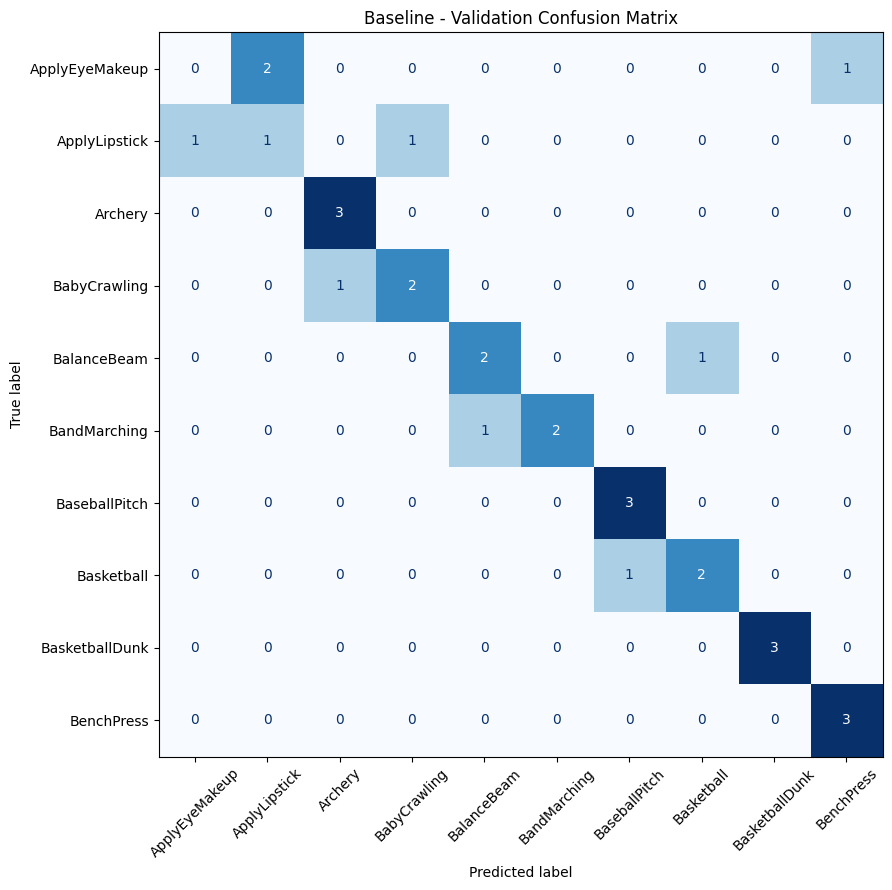


COMPUTATIONAL COST
Classifier Parameters: 12970
Model Size (MB): 0.081
Hardware: CPU
Total Cell Time (s): 15.03

Baseline Model Saved: /content/drive/MyDrive/Video_Action_Recognition/checkpoints/baseline_hog_logistic.joblib
CELL 5 COMPLETED


In [7]:

import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from skimage.feature import hog

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("=" * 55)
print("CELL 5: BASELINE MODEL")
print("=" * 55)

baseline_start = time.time()

# 1. HOG feature extraction
def extract_hog_features(video):
    selected_frames = [2, 6, 10, 14]
    features = []

    for idx in selected_frames:
        frame = np.asarray(video[idx])

        gray = cv2.cvtColor(
            frame,
            cv2.COLOR_RGB2GRAY
        )

        feature = hog(
            gray,
            orientations=9,
            pixels_per_cell=(16, 16),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            feature_vector=True
        )

        features.append(feature)

    return np.mean(features, axis=0)


# 2. Extract or restore cached HOG features
HOG_CACHE = (
    PROJECT_DIR / "experiments" /
    "hog_features.npy"
)

if HOG_CACHE.exists():
    X_hog = np.load(HOG_CACHE)

    if len(X_hog) != len(X):
        raise ValueError("HOG cache size mismatch")

    print("Loaded cached HOG features.")

else:
    print("Extracting HOG features...")

    X_hog = np.array([
        extract_hog_features(X[i])
        for i in tqdm(range(len(X)))
    ], dtype=np.float32)

    np.save(HOG_CACHE, X_hog)

print("HOG Features Shape:", X_hog.shape)

# 3. Prepare train/validation data
X_train_hog = X_hog[train_idx]
X_val_hog = X_hog[val_idx]

y_train = y[train_idx]
y_val = y[val_idx]

print("Training Samples:", len(y_train))
print("Validation Samples:", len(y_val))

# 4. Train using three random seeds
SEEDS = [42, 123, 2026]

results = []
models = []

for seed in SEEDS:
    print(f"\nTraining Baseline - Seed {seed}")

    model = make_pipeline(
        StandardScaler(),
        SGDClassifier(
            loss="log_loss",
            penalty="l2",
            alpha=0.001,
            max_iter=1200,
            tol=1e-3,
            random_state=seed
        )
    )

    start = time.time()

    model.fit(X_train_hog, y_train)

    train_time = time.time() - start

    y_pred = model.predict(X_val_hog)

    acc = accuracy_score(y_val, y_pred)
    macro_f1 = f1_score(
        y_val,
        y_pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "model": "HOG_Logistic_SGD",
        "seed": seed,
        "val_accuracy": acc,
        "val_macro_f1": macro_f1,
        "train_time_sec": train_time
    })

    models.append(model)

    print(f"Accuracy: {acc:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Training Time: {train_time:.2f}s")

# 5. Results summary
results_df = pd.DataFrame(results)

print("\nBASELINE RESULTS")
print(results_df.to_string(index=False))

print("\nMEAN AND STANDARD DEVIATION")

for metric in ["val_accuracy", "val_macro_f1"]:
    print(
        f"{metric}: "
        f"{results_df[metric].mean():.4f} "
        f"+/- {results_df[metric].std():.4f}"
    )

# 6. Save best validation model
best_idx = results_df["val_macro_f1"].idxmax()
best_model = models[best_idx]

model_path = (
    PROJECT_DIR / "checkpoints" /
    "baseline_hog_logistic.joblib"
)

joblib.dump(best_model, model_path)

results_df.to_csv(
    PROJECT_DIR / "experiments" /
    "baseline_results.csv",
    index=False
)

# 7. Per-class validation report
best_pred = best_model.predict(X_val_hog)

report = classification_report(
    y_val,
    best_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).T

report_df.to_csv(
    PROJECT_DIR / "experiments" /
    "baseline_classification_report.csv"
)

print("\nPER-CLASS CLASSIFICATION REPORT")
print(
    classification_report(
        y_val,
        best_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)

# 8. Confusion matrix
cm = confusion_matrix(
    y_val,
    best_pred,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(11, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

plt.title("Baseline - Validation Confusion Matrix")
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "experiments" /
    "baseline_confusion_matrix.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# 9. Computational cost
classifier = best_model.named_steps["sgdclassifier"]

param_count = (
    classifier.coef_.size +
    classifier.intercept_.size
)

model_size_mb = (
    model_path.stat().st_size / 1024**2
)

print("\nCOMPUTATIONAL COST")
print("Classifier Parameters:", param_count)
print("Model Size (MB):", round(model_size_mb, 3))
print("Hardware: CPU")
print(
    "Total Cell Time (s):",
    round(time.time() - baseline_start, 2)
)

print("\nBaseline Model Saved:", model_path)

print("=" * 55)
print("CELL 5 COMPLETED")


In [8]:

import torch
import torch.nn as nn
import numpy as np

from torch.utils.data import Dataset, DataLoader

print("=" * 55)
print("CELL 6: 3D CNN ARCHITECTURE")
print("=" * 55)

# Training configuration
BATCH_SIZE = 8
NUM_CLASSES = len(class_names)

# Dataset class
class VideoDataset(Dataset):

    def __init__(self, indices, augment=False):
        self.indices = np.asarray(indices)
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):

        video_id = int(self.indices[index])

        video = np.array(
            X[video_id],
            copy=True
        )

        label = int(y[video_id])

        # Optional training-only augmentation
        if self.augment and np.random.rand() < 0.5:
            video = video[:, :, ::-1, :].copy()

        # Shape: T,H,W,C -> C,T,H,W
        video = torch.from_numpy(
            video
        ).permute(3, 0, 1, 2)

        # Normalize pixels to [0, 1]
        video = video.float() / 255.0

        return video, label


# Create datasets
# Disable augmentation for the initial comparison
train_dataset = VideoDataset(
    train_idx,
    augment=False
)

val_dataset = VideoDataset(
    val_idx,
    augment=False
)

# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)


# Build 3D CNN from scratch
class Simple3DCNN(nn.Module):

    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv3d(
                3, 16,
                kernel_size=3,
                stride=(1, 2, 2),
                padding=1
            ),
            nn.BatchNorm3d(16),
            nn.ReLU(inplace=True),

            nn.MaxPool3d((1, 2, 2)),

            nn.Conv3d(
                16, 32,
                kernel_size=3,
                stride=(2, 2, 2),
                padding=1
            ),
            nn.BatchNorm3d(32),
            nn.ReLU(inplace=True),

            nn.Conv3d(
                32, 64,
                kernel_size=3,
                stride=(2, 2, 2),
                padding=1
            ),
            nn.BatchNorm3d(64),
            nn.ReLU(inplace=True),

            nn.Conv3d(
                64, 96,
                kernel_size=3,
                stride=(2, 2, 2),
                padding=1
            ),
            nn.BatchNorm3d(96),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool3d((1, 1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(96, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x


# Initialize model
model = Simple3DCNN(
    num_classes=NUM_CLASSES
).to(DEVICE)

# Count parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nMODEL INFORMATION")
print("Model: Simple3DCNN")
print("Device:", DEVICE)
print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)

# Verify data and model compatibility
sample_batch, sample_labels = next(
    iter(train_loader)
)

print("\nINPUT SHAPE:", sample_batch.shape)
print("LABELS SHAPE:", sample_labels.shape)

model.eval()

with torch.no_grad():
    output = model(
        sample_batch[:2].to(DEVICE)
    )

print("MODEL OUTPUT SHAPE:", output.shape)

assert output.shape == (2, NUM_CLASSES)

print("\nTRAINING BATCHES:", len(train_loader))
print("VALIDATION BATCHES:", len(val_loader))

print("=" * 55)
print("CELL 6 COMPLETED")


CELL 6: 3D CNN ARCHITECTURE

MODEL INFORMATION
Model: Simple3DCNN
Device: cuda
Total Parameters: 237898
Trainable Parameters: 237898

INPUT SHAPE: torch.Size([8, 3, 16, 112, 112])
LABELS SHAPE: torch.Size([8])
MODEL OUTPUT SHAPE: torch.Size([2, 10])

TRAINING BATCHES: 38
VALIDATION BATCHES: 4
CELL 6 COMPLETED


CELL 7: 3D CNN TRAINING

TRAINING 3D CNN - SEED 42
Epoch [1/8] | Train Loss: 2.1135 | Train Acc: 0.2100 | Val Loss: 2.1642 | Val Acc: 0.1333 | Val F1: 0.0619
Epoch [2/8] | Train Loss: 1.8140 | Train Acc: 0.3800 | Val Loss: 1.8653 | Val Acc: 0.3333 | Val F1: 0.2650
Epoch [3/8] | Train Loss: 1.6819 | Train Acc: 0.4667 | Val Loss: 2.0413 | Val Acc: 0.2667 | Val F1: 0.1744
Epoch [4/8] | Train Loss: 1.4373 | Train Acc: 0.5600 | Val Loss: 2.8428 | Val Acc: 0.1667 | Val F1: 0.0929
Epoch [5/8] | Train Loss: 1.3736 | Train Acc: 0.5900 | Val Loss: 1.5372 | Val Acc: 0.4333 | Val F1: 0.3848
Epoch [6/8] | Train Loss: 1.1687 | Train Acc: 0.6667 | Val Loss: 1.5715 | Val Acc: 0.4333 | Val F1: 0.4095
Epoch [7/8] | Train Loss: 1.0669 | Train Acc: 0.6967 | Val Loss: 1.4903 | Val Acc: 0.5000 | Val F1: 0.4123
Epoch [8/8] | Train Loss: 0.9982 | Train Acc: 0.7533 | Val Loss: 2.4124 | Val Acc: 0.3333 | Val F1: 0.2939

SEED 42 COMPLETED
Best Epoch: 7
Best Val Accuracy: 0.5000
Best Val Macro-F1: 0.4123
Training

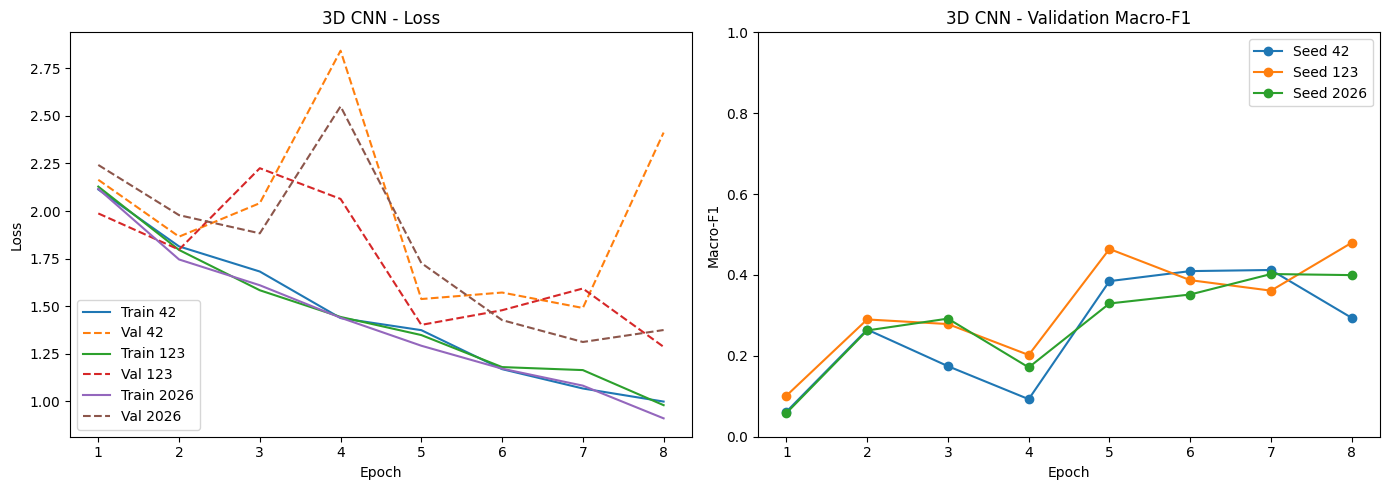

CELL 7 COMPLETED


In [9]:

import time
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader

print("=" * 55)
print("CELL 7: 3D CNN TRAINING")
print("=" * 55)

# 1. Training configuration
SEEDS = [42, 123, 2026]
EPOCHS = 8
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4

USE_AMP = DEVICE.type == "cuda"

criterion = nn.CrossEntropyLoss()

all_results = []
all_history = []

# 2. Reproducibility
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# 3. Validation function
@torch.no_grad()
def evaluate_3dcnn(model, loader):

    model.eval()

    total_loss = 0
    predictions = []
    targets = []

    for videos, labels in loader:

        videos = videos.to(DEVICE)
        labels = labels.to(DEVICE)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP
        ):
            outputs = model(videos)
            loss = criterion(outputs, labels)

        total_loss += (
            loss.item() * labels.size(0)
        )

        preds = outputs.argmax(dim=1)

        predictions.extend(
            preds.cpu().numpy()
        )
        targets.extend(
            labels.cpu().numpy()
        )

    val_loss = total_loss / len(loader.dataset)

    val_acc = accuracy_score(
        targets, predictions
    )

    val_f1 = f1_score(
        targets,
        predictions,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    return val_loss, val_acc, val_f1


# 4. Training loop for all seeds
for seed in SEEDS:

    print("\n" + "=" * 55)
    print(f"TRAINING 3D CNN - SEED {seed}")
    print("=" * 55)

    set_seed(seed)

    # Seed-specific data shuffling
    generator = torch.Generator()
    generator.manual_seed(seed)

    seed_train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=USE_AMP
    )

    # Fresh model for every seed
    model = Simple3DCNN(
        num_classes=NUM_CLASSES
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )

    best_f1 = -1.0
    best_loss = float("inf")
    best_epoch = 0
    best_acc = 0.0

    checkpoint_path = (
        PROJECT_DIR / "checkpoints" /
        f"3dcnn_seed_{seed}.pt"
    )

    if USE_AMP:
        torch.cuda.reset_peak_memory_stats()

    start_time = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for videos, labels in seed_train_loader:

            videos = videos.to(
                DEVICE,
                non_blocking=True
            )
            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=DEVICE.type,
                enabled=USE_AMP
            ):
                outputs = model(videos)

                loss = criterion(
                    outputs, labels
                )

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            batch_size = labels.size(0)

            running_loss += (
                loss.item() * batch_size
            )

            correct += (
                outputs.argmax(1) == labels
            ).sum().item()

            total += batch_size

        train_loss = running_loss / total
        train_acc = correct / total

        # Validation only, not test
        val_loss, val_acc, val_f1 = evaluate_3dcnn(
            model, val_loader
        )

        all_history.append({
            "model": "3D_CNN",
            "seed": seed,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1
        })

        print(
            f"Epoch [{epoch}/{EPOCHS}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val F1: {val_f1:.4f}",
            flush=True
        )

        # Save best model using validation F1
        is_best = (
            val_f1 > best_f1 + 1e-8
            or (
                abs(val_f1 - best_f1) <= 1e-8
                and val_loss < best_loss
            )
        )

        if is_best:

            best_f1 = val_f1
            best_loss = val_loss
            best_acc = val_acc
            best_epoch = epoch

            torch.save({
                "model_state_dict": model.state_dict(),
                "seed": seed,
                "epoch": epoch,
                "val_macro_f1": val_f1,
                "val_accuracy": val_acc,
                "class_names": class_names,
                "num_frames": NUM_FRAMES,
                "frame_size": FRAME_SIZE,
                "learning_rate": LEARNING_RATE
            }, checkpoint_path)

    if USE_AMP:
        torch.cuda.synchronize()

    training_time = time.perf_counter() - start_time

    peak_memory = (
        torch.cuda.max_memory_allocated() / 1024**2
        if USE_AMP else 0
    )

    model_size = (
        checkpoint_path.stat().st_size / 1024**2
    )

    all_results.append({
        "model": "3D_CNN",
        "seed": seed,
        "best_epoch": best_epoch,
        "val_accuracy": best_acc,
        "val_macro_f1": best_f1,
        "train_time_sec": training_time,
        "parameters": sum(
            p.numel() for p in model.parameters()
        ),
        "model_size_mb": model_size,
        "peak_gpu_memory_mb": peak_memory
    })

    print(f"\nSEED {seed} COMPLETED")
    print(f"Best Epoch: {best_epoch}")
    print(f"Best Val Accuracy: {best_acc:.4f}")
    print(f"Best Val Macro-F1: {best_f1:.4f}")
    print(f"Training Time: {training_time:.2f}s")
    print(f"Checkpoint Saved: {checkpoint_path}")

    # Save progress after every seed
    pd.DataFrame(all_results).to_csv(
        PROJECT_DIR / "experiments" /
        "3dcnn_results.csv",
        index=False
    )

    pd.DataFrame(all_history).to_csv(
        PROJECT_DIR / "experiments" /
        "3dcnn_training_history.csv",
        index=False
    )

    del model, optimizer, scaler

    if USE_AMP:
        torch.cuda.empty_cache()


# 5. Final results
results_3dcnn = pd.DataFrame(all_results)
history_3dcnn = pd.DataFrame(all_history)

print("\n" + "=" * 55)
print("FINAL 3D CNN RESULTS")
print("=" * 55)

print(results_3dcnn.to_string(index=False))

print("\nMEAN AND STANDARD DEVIATION")

for metric in ["val_accuracy", "val_macro_f1"]:
    print(
        f"{metric}: "
        f"{results_3dcnn[metric].mean():.4f} "
        f"+/- "
        f"{results_3dcnn[metric].std():.4f}"
    )


# 6. Save overall best validation checkpoint
best_row = results_3dcnn.loc[
    results_3dcnn["val_macro_f1"].idxmax()
]

best_seed = int(best_row["seed"])

shutil.copy2(
    PROJECT_DIR / "checkpoints" /
    f"3dcnn_seed_{best_seed}.pt",
    PROJECT_DIR / "checkpoints" /
    "best_3dcnn.pt"
)

print("\nBest Validation Seed:", best_seed)


# 7. Learning curves
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

for seed in SEEDS:

    h = history_3dcnn[
        history_3dcnn["seed"] == seed
    ]

    axes[0].plot(
        h["epoch"],
        h["train_loss"],
        label=f"Train {seed}"
    )

    axes[0].plot(
        h["epoch"],
        h["val_loss"],
        linestyle="--",
        label=f"Val {seed}"
    )

    axes[1].plot(
        h["epoch"],
        h["val_macro_f1"],
        marker="o",
        label=f"Seed {seed}"
    )

axes[0].set_title("3D CNN - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].set_title("3D CNN - Validation Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "experiments" /
    "3dcnn_learning_curves.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("=" * 55)
print("CELL 7 COMPLETED")


CELL 7B: 3D CNN - 20 EPOCH EXPERIMENT

TRAINING SEED 42
Epoch [01/20] | Train Acc: 0.2100 | Val Acc: 0.1333 | Val F1: 0.0619 | Val Loss: 2.1642
Epoch [02/20] | Train Acc: 0.3800 | Val Acc: 0.3333 | Val F1: 0.2650 | Val Loss: 1.8653
Epoch [03/20] | Train Acc: 0.4667 | Val Acc: 0.2667 | Val F1: 0.1744 | Val Loss: 2.0413
Epoch [04/20] | Train Acc: 0.5600 | Val Acc: 0.1667 | Val F1: 0.0929 | Val Loss: 2.8428
Epoch [05/20] | Train Acc: 0.5900 | Val Acc: 0.4333 | Val F1: 0.3848 | Val Loss: 1.5372
Epoch [06/20] | Train Acc: 0.6667 | Val Acc: 0.4333 | Val F1: 0.4095 | Val Loss: 1.5715
Epoch [07/20] | Train Acc: 0.6967 | Val Acc: 0.5000 | Val F1: 0.4123 | Val Loss: 1.4903
Epoch [08/20] | Train Acc: 0.7533 | Val Acc: 0.3333 | Val F1: 0.2939 | Val Loss: 2.4124
Epoch [09/20] | Train Acc: 0.7233 | Val Acc: 0.5333 | Val F1: 0.4795 | Val Loss: 1.6402
Epoch [10/20] | Train Acc: 0.7600 | Val Acc: 0.5333 | Val F1: 0.4867 | Val Loss: 1.3196
Epoch [11/20] | Train Acc: 0.8233 | Val Acc: 0.6667 | Val F1: 0.

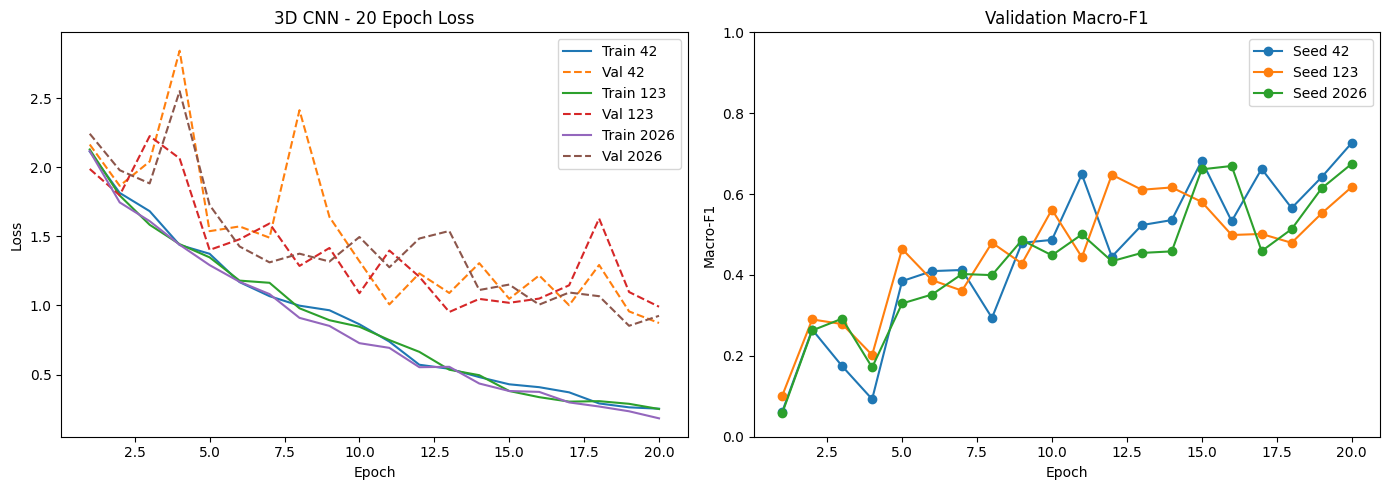

CELL 7B COMPLETED


In [10]:

import time
import random
import shutil
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

print("=" * 55)
print("CELL 7B: 3D CNN - 20 EPOCH EXPERIMENT")
print("=" * 55)

# Experiment configuration
NEW_EPOCHS = 20
NEW_LR = 0.001
NEW_WEIGHT_DECAY = 1e-4
EXPERIMENT_NAME = "3dcnn_20ep"

new_results = []
new_history = []

for seed in [42, 123, 2026]:

    print(f"\nTRAINING SEED {seed}")

    set_seed(seed)

    generator = torch.Generator()
    generator.manual_seed(seed)

    loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=USE_AMP
    )

    # Fresh model
    model = Simple3DCNN(
        num_classes=NUM_CLASSES
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=NEW_LR,
        weight_decay=NEW_WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )

    best_f1 = -1.0
    best_loss = float("inf")
    best_epoch = 0
    best_acc = 0.0

    checkpoint_path = (
        PROJECT_DIR / "checkpoints" /
        f"{EXPERIMENT_NAME}_seed_{seed}.pt"
    )

    if USE_AMP:
        torch.cuda.reset_peak_memory_stats()

    start_time = time.perf_counter()

    for epoch in range(1, NEW_EPOCHS + 1):

        model.train()

        total_loss = 0.0
        correct = 0
        total = 0

        for videos, labels in loader:

            videos = videos.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad(
                set_to_none=True
            )

            with torch.amp.autocast(
                device_type=DEVICE.type,
                enabled=USE_AMP
            ):
                outputs = model(videos)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            batch_n = labels.size(0)

            total_loss += loss.item() * batch_n
            correct += (
                outputs.argmax(1) == labels
            ).sum().item()

            total += batch_n

        train_loss = total_loss / total
        train_acc = correct / total

        val_loss, val_acc, val_f1 = evaluate_3dcnn(
            model,
            val_loader
        )

        new_history.append({
            "model": EXPERIMENT_NAME,
            "seed": seed,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1
        })

        print(
            f"Epoch [{epoch:02d}/{NEW_EPOCHS}] | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val F1: {val_f1:.4f} | "
            f"Val Loss: {val_loss:.4f}",
            flush=True
        )

        # Save best validation checkpoint
        is_best = (
            val_f1 > best_f1 + 1e-8
            or (
                abs(val_f1 - best_f1) <= 1e-8
                and val_loss < best_loss
            )
        )

        if is_best:

            best_f1 = val_f1
            best_acc = val_acc
            best_loss = val_loss
            best_epoch = epoch

            torch.save({
                "model_state_dict": model.state_dict(),
                "seed": seed,
                "epoch": epoch,
                "val_accuracy": val_acc,
                "val_macro_f1": val_f1,
                "class_names": class_names,
                "num_frames": NUM_FRAMES,
                "frame_size": FRAME_SIZE
            }, checkpoint_path)

    if USE_AMP:
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    peak_memory = (
        torch.cuda.max_memory_allocated() / 1024**2
        if USE_AMP else 0.0
    )

    new_results.append({
        "model": EXPERIMENT_NAME,
        "epochs_budget": NEW_EPOCHS,
        "seed": seed,
        "best_epoch": best_epoch,
        "val_accuracy": best_acc,
        "val_macro_f1": best_f1,
        "train_time_sec": elapsed,
        "parameters": sum(
            p.numel() for p in model.parameters()
        ),
        "model_size_mb": (
            checkpoint_path.stat().st_size / 1024**2
        ),
        "peak_gpu_memory_mb": peak_memory
    })

    # Save after each seed
    pd.DataFrame(new_results).to_csv(
        PROJECT_DIR / "experiments" /
        f"{EXPERIMENT_NAME}_results.csv",
        index=False
    )

    pd.DataFrame(new_history).to_csv(
        PROJECT_DIR / "experiments" /
        f"{EXPERIMENT_NAME}_history.csv",
        index=False
    )

    print(
        f"\nSEED {seed} FINISHED | "
        f"Best Epoch: {best_epoch} | "
        f"Best F1: {best_f1:.4f}"
    )

    del model, optimizer, scaler

    if USE_AMP:
        torch.cuda.empty_cache()


# Experiment results
results_20 = pd.DataFrame(new_results)
history_20 = pd.DataFrame(new_history)

print("\nFINAL 20-EPOCH RESULTS")
print(results_20.to_string(index=False))

print("\nMEAN AND STANDARD DEVIATION")

for metric in ["val_accuracy", "val_macro_f1"]:
    print(
        f"{metric}: "
        f"{results_20[metric].mean():.4f} "
        f"+/- {results_20[metric].std():.4f}"
    )

# Best 20-epoch checkpoint
best_row = results_20.loc[
    results_20["val_macro_f1"].idxmax()
]

best_seed = int(best_row["seed"])

shutil.copy2(
    PROJECT_DIR / "checkpoints" /
    f"{EXPERIMENT_NAME}_seed_{best_seed}.pt",
    PROJECT_DIR / "checkpoints" /
    "best_3dcnn_20ep.pt"
)

# Compare with previous experiment
old_results = pd.read_csv(
    PROJECT_DIR / "experiments" /
    "3dcnn_results.csv"
)

comparison = pd.DataFrame([
    {
        "epoch_budget": 8,
        "mean_accuracy": old_results[
            "val_accuracy"
        ].mean(),
        "mean_macro_f1": old_results[
            "val_macro_f1"
        ].mean()
    },
    {
        "epoch_budget": 20,
        "mean_accuracy": results_20[
            "val_accuracy"
        ].mean(),
        "mean_macro_f1": results_20[
            "val_macro_f1"
        ].mean()
    }
])

comparison.to_csv(
    PROJECT_DIR / "experiments" /
    "3dcnn_epoch_study.csv",
    index=False
)

print("\n8 vs 20 EPOCH COMPARISON")
print(comparison.to_string(index=False))

# Visualization
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

for seed in [42, 123, 2026]:

    h = history_20[
        history_20["seed"] == seed
    ]

    axes[0].plot(
        h["epoch"],
        h["train_loss"],
        label=f"Train {seed}"
    )

    axes[0].plot(
        h["epoch"],
        h["val_loss"],
        linestyle="--",
        label=f"Val {seed}"
    )

    axes[1].plot(
        h["epoch"],
        h["val_macro_f1"],
        marker="o",
        label=f"Seed {seed}"
    )

axes[0].set_title("3D CNN - 20 Epoch Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].set_title("Validation Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "experiments" /
    "3dcnn_20ep_curves.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("=" * 55)
print("CELL 7B COMPLETED")


CELL 7D: 3D CNN WITH EARLY STOPPING

TRAINING SEED 42
Epoch [01/50] | Train Acc: 0.2100 | Val Acc: 0.1333 | Val F1: 0.0619 | Patience: 0/12
Epoch [02/50] | Train Acc: 0.3800 | Val Acc: 0.3333 | Val F1: 0.2650 | Patience: 0/12
Epoch [03/50] | Train Acc: 0.4667 | Val Acc: 0.2667 | Val F1: 0.1744 | Patience: 1/12
Epoch [04/50] | Train Acc: 0.5600 | Val Acc: 0.1667 | Val F1: 0.0929 | Patience: 2/12
Epoch [05/50] | Train Acc: 0.5900 | Val Acc: 0.4333 | Val F1: 0.3848 | Patience: 0/12
Epoch [06/50] | Train Acc: 0.6667 | Val Acc: 0.4333 | Val F1: 0.4095 | Patience: 0/12
Epoch [07/50] | Train Acc: 0.6967 | Val Acc: 0.5000 | Val F1: 0.4123 | Patience: 1/12
Epoch [08/50] | Train Acc: 0.7533 | Val Acc: 0.3333 | Val F1: 0.2939 | Patience: 2/12
Epoch [09/50] | Train Acc: 0.7233 | Val Acc: 0.5333 | Val F1: 0.4795 | Patience: 0/12
Epoch [10/50] | Train Acc: 0.7600 | Val Acc: 0.5333 | Val F1: 0.4867 | Patience: 0/12
Epoch [11/50] | Train Acc: 0.8233 | Val Acc: 0.6667 | Val F1: 0.6488 | Patience: 0/12


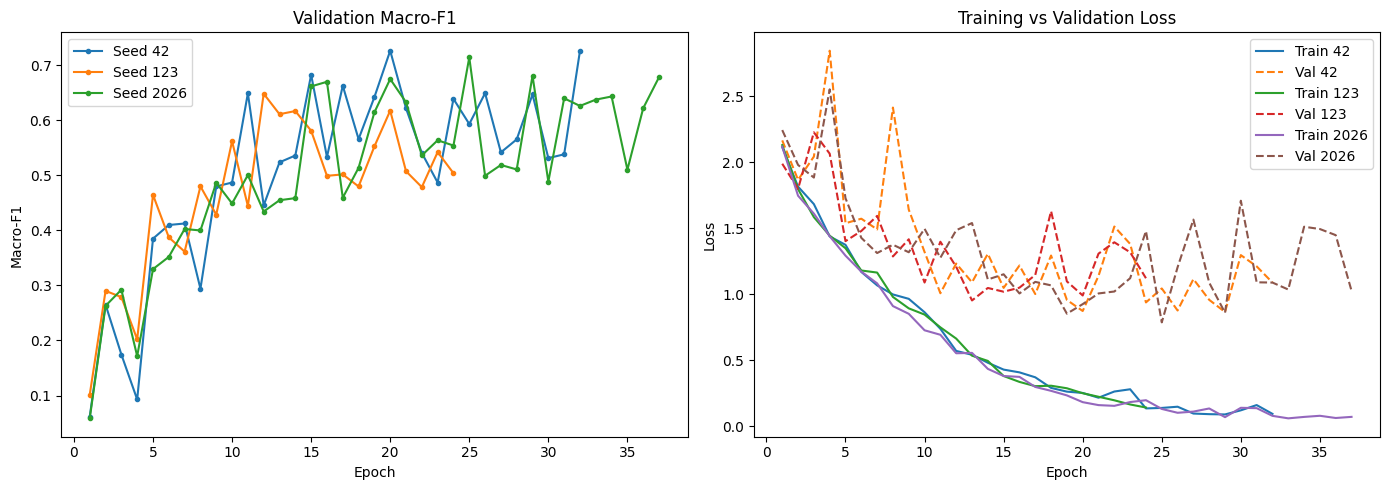

CELL 7D COMPLETED


In [11]:

import time
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

print("=" * 55)
print("CELL 7D: 3D CNN WITH EARLY STOPPING")
print("=" * 55)

# Experiment Configuration
MAX_EPOCHS = 50
PATIENCE = 12
MIN_EPOCHS = 20
MIN_DELTA = 0.005

LR = 0.001
WEIGHT_DECAY = 1e-4

SEEDS = [42, 123, 2026]
EXPERIMENT = "3dcnn_50ep_earlystop"

results_es = []
history_es = []

for seed in SEEDS:

    print("\n" + "=" * 55)
    print(f"TRAINING SEED {seed}")
    print("=" * 55)

    set_seed(seed)

    generator = torch.Generator()
    generator.manual_seed(seed)

    loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=USE_AMP
    )

    model = Simple3DCNN(
        num_classes=NUM_CLASSES
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )

    best_f1 = -1.0
    best_loss = float("inf")
    best_acc = 0.0
    best_epoch = 0

    # Early stopping variables
    stopping_reference = -1.0
    patience_counter = 0

    checkpoint_path = (
        PROJECT_DIR / "checkpoints" /
        f"{EXPERIMENT}_seed_{seed}.pt"
    )

    if USE_AMP:
        torch.cuda.reset_peak_memory_stats()

    start_time = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for videos, labels in loader:

            videos = videos.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=DEVICE.type,
                enabled=USE_AMP
            ):
                outputs = model(videos)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            n = labels.size(0)

            running_loss += loss.item() * n

            correct += (
                outputs.argmax(1) == labels
            ).sum().item()

            total += n

        train_loss = running_loss / total
        train_acc = correct / total

        val_loss, val_acc, val_f1 = evaluate_3dcnn(
            model,
            val_loader
        )

        history_es.append({
            "seed": seed,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1
        })

        # Save the best checkpoint
        is_best = (
            val_f1 > best_f1 + 1e-8
            or (
                abs(val_f1 - best_f1) <= 1e-8
                and val_loss < best_loss
            )
        )

        if is_best:

            best_f1 = val_f1
            best_loss = val_loss
            best_acc = val_acc
            best_epoch = epoch

            torch.save({
                "model_state_dict": model.state_dict(),
                "seed": seed,
                "epoch": epoch,
                "val_accuracy": val_acc,
                "val_macro_f1": val_f1,
                "class_names": class_names,
                "num_frames": NUM_FRAMES,
                "frame_size": FRAME_SIZE
            }, checkpoint_path)

        # Early stopping: significant improvement
        if val_f1 > stopping_reference + MIN_DELTA:

            stopping_reference = val_f1
            patience_counter = 0

        else:
            patience_counter += 1

        print(
            f"Epoch [{epoch:02d}/{MAX_EPOCHS}] | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val F1: {val_f1:.4f} | "
            f"Patience: {patience_counter}/{PATIENCE}",
            flush=True
        )

        if (
            epoch >= MIN_EPOCHS
            and patience_counter >= PATIENCE
        ):
            print(
                f"\nEARLY STOPPING TRIGGERED "
                f"AT EPOCH {epoch}"
            )
            break

    if USE_AMP:
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    results_es.append({
        "model": EXPERIMENT,
        "seed": seed,
        "epochs_run": epoch,
        "best_epoch": best_epoch,
        "val_accuracy": best_acc,
        "val_macro_f1": best_f1,
        "train_time_sec": elapsed,
        "parameters": sum(
            p.numel() for p in model.parameters()
        ),
        "model_size_mb": (
            checkpoint_path.stat().st_size / 1024**2
        ),
        "peak_gpu_memory_mb": (
            torch.cuda.max_memory_allocated() / 1024**2
            if USE_AMP else 0
        )
    })

    # Save every seed's results
    pd.DataFrame(results_es).to_csv(
        PROJECT_DIR / "experiments" /
        f"{EXPERIMENT}_results.csv",
        index=False
    )

    pd.DataFrame(history_es).to_csv(
        PROJECT_DIR / "experiments" /
        f"{EXPERIMENT}_history.csv",
        index=False
    )

    print(f"\nSEED {seed} COMPLETED")
    print("Epochs Run:", epoch)
    print("Best Epoch:", best_epoch)
    print("Best Validation F1:", round(best_f1, 4))
    print("Best Accuracy:", round(best_acc, 4))

    del model, optimizer, scaler

    if USE_AMP:
        torch.cuda.empty_cache()


# Final results
results_df_es = pd.DataFrame(results_es)
history_df_es = pd.DataFrame(history_es)

print("\nFINAL EARLY STOPPING RESULTS")
print(results_df_es.to_string(index=False))

print("\nMEAN AND STANDARD DEVIATION")

for metric in ["val_accuracy", "val_macro_f1"]:
    print(
        f"{metric}: "
        f"{results_df_es[metric].mean():.4f} "
        f"+/- {results_df_es[metric].std():.4f}"
    )

# Learning Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for seed in SEEDS:

    h = history_df_es[
        history_df_es["seed"] == seed
    ]

    axes[0].plot(
        h["epoch"],
        h["val_macro_f1"],
        marker=".",
        label=f"Seed {seed}"
    )

    axes[1].plot(
        h["epoch"],
        h["train_loss"],
        label=f"Train {seed}"
    )

    axes[1].plot(
        h["epoch"],
        h["val_loss"],
        linestyle="--",
        label=f"Val {seed}"
    )

axes[0].set_title("Validation Macro-F1")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Macro-F1")
axes[0].legend()

axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "experiments" /
    f"{EXPERIMENT}_curves.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("=" * 55)
print("CELL 7D COMPLETED")


CELL 8: 3D CNN VALIDATION & ERROR ANALYSIS
Best Seed: 42
Best Epoch: 20

VALIDATION RESULTS
Accuracy: 0.7333
Macro-F1: 0.7260
Inference ms/video: 6.625

PER-CLASS REPORT
                precision    recall  f1-score   support

ApplyEyeMakeup       1.00      1.00      1.00         3
 ApplyLipstick       1.00      1.00      1.00         3
       Archery       0.50      0.33      0.40         3
  BabyCrawling       0.75      1.00      0.86         3
   BalanceBeam       0.60      1.00      0.75         3
  BandMarching       1.00      0.33      0.50         3
 BaseballPitch       0.67      0.67      0.67         3
    Basketball       0.25      0.33      0.29         3
BasketballDunk       1.00      1.00      1.00         3
    BenchPress       1.00      0.67      0.80         3

      accuracy                           0.73        30
     macro avg       0.78      0.73      0.73        30
  weighted avg       0.78      0.73      0.73        30



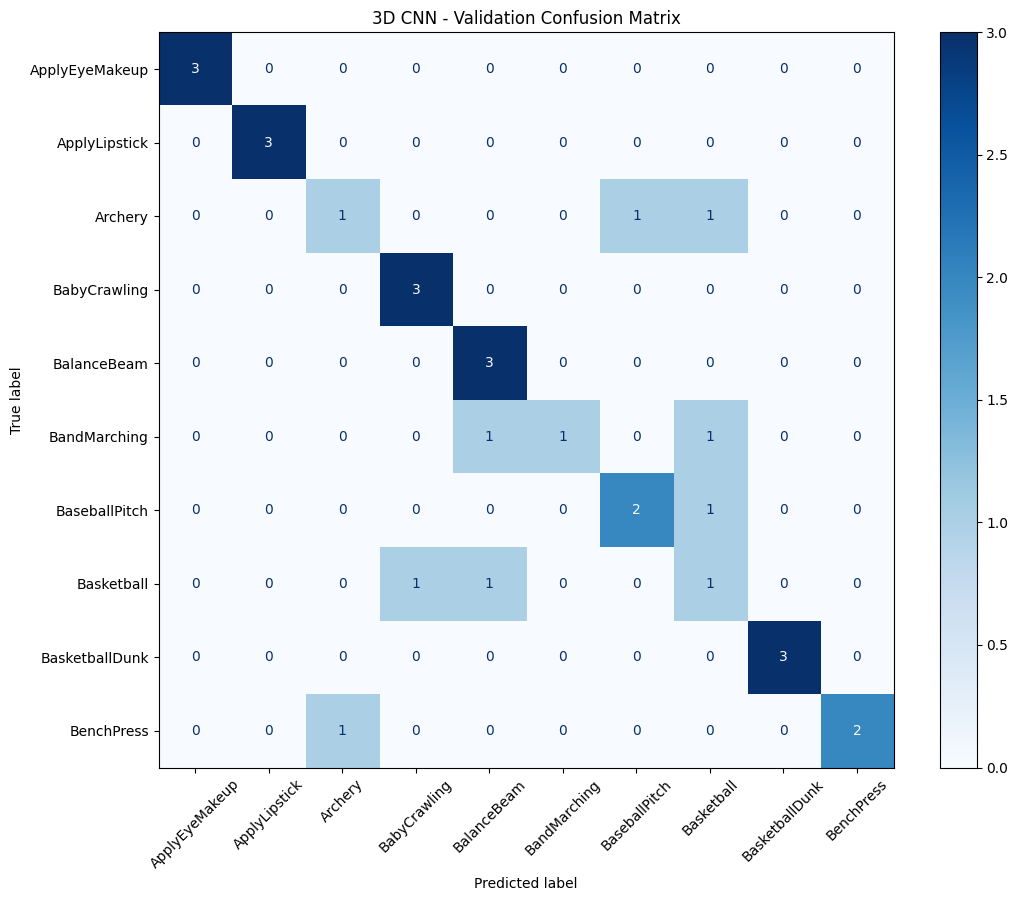


CORRECT: 22
ERRORS: 8

MISCLASSIFIED VIDEOS
   true_label predicted_label  confidence
      Archery   BaseballPitch    0.823868
   Basketball    BabyCrawling    0.645534
   Basketball     BalanceBeam    0.626275
      Archery      Basketball    0.564397
 BandMarching     BalanceBeam    0.458239
   BenchPress         Archery    0.448525
BaseballPitch      Basketball    0.439813
 BandMarching      Basketball    0.380463


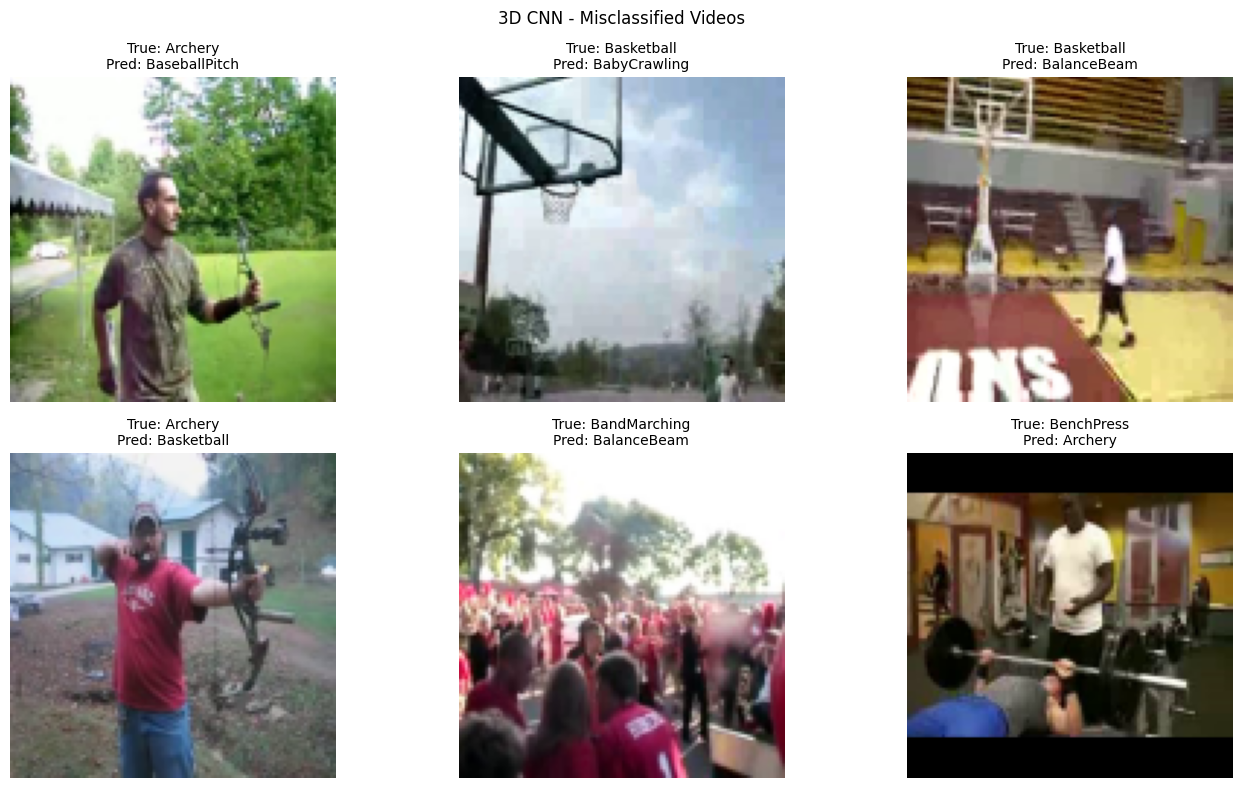

CELL 8 COMPLETED


In [12]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)

print("=" * 55)
print("CELL 8: 3D CNN VALIDATION & ERROR ANALYSIS")
print("=" * 55)

# Select best seed from Early Stopping
exp_name = "3dcnn_50ep_earlystop"

results = pd.read_csv(
    PROJECT_DIR / "experiments" /
    f"{exp_name}_results.csv"
)

best_row = results.loc[
    results["val_macro_f1"].idxmax()
]

best_seed = int(best_row["seed"])

checkpoint_path = (
    PROJECT_DIR / "checkpoints" /
    f"{exp_name}_seed_{best_seed}.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

best_cnn = Simple3DCNN(
    num_classes=NUM_CLASSES
).to(DEVICE)

best_cnn.load_state_dict(
    checkpoint["model_state_dict"]
)
best_cnn.eval()

print("Best Seed:", best_seed)
print("Best Epoch:", checkpoint["epoch"])

# Warm-up
with torch.inference_mode():
    videos, _ = next(iter(val_loader))
    with torch.amp.autocast(
        device_type=DEVICE.type,
        enabled=USE_AMP
    ):
        _ = best_cnn(videos.to(DEVICE))

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

# Validation predictions
predictions = []
targets = []
confidences = []

start = time.perf_counter()

with torch.inference_mode():
    for videos, labels in val_loader:
        videos = videos.to(DEVICE)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP
        ):
            outputs = best_cnn(videos)

        probs = torch.softmax(
            outputs.float(), dim=1
        )

        conf, pred = probs.max(dim=1)

        predictions.extend(pred.cpu().tolist())
        targets.extend(labels.tolist())
        confidences.extend(conf.cpu().tolist())

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

elapsed = time.perf_counter() - start

y_true = np.array(targets)
y_pred = np.array(predictions)

acc = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true, y_pred,
    labels=list(range(NUM_CLASSES)),
    average="macro",
    zero_division=0
)

print("\nVALIDATION RESULTS")
print(f"Accuracy: {acc:.4f}")
print(f"Macro-F1: {macro_f1:.4f}")
print(
    "Inference ms/video:",
    round(elapsed / len(y_true) * 1000, 3)
)

# Per-class report
report = classification_report(
    y_true, y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
)

print("\nPER-CLASS REPORT")
print(report)

pd.DataFrame(
    classification_report(
        y_true, y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
).T.to_csv(
    PROJECT_DIR / "experiments" /
    "3dcnn_final_per_class.csv"
)

# Confusion Matrix
cm = confusion_matrix(
    y_true, y_pred,
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(11, 9))

disp = ConfusionMatrixDisplay(
    cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("3D CNN - Validation Confusion Matrix")
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "experiments" /
    "3dcnn_final_confusion_matrix.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# Save predictions and errors
pred_df = pd.DataFrame({
    "dataset_index": val_idx,
    "true_label": [
        class_names[i] for i in y_true
    ],
    "predicted_label": [
        class_names[i] for i in y_pred
    ],
    "confidence": confidences
})

pred_df["correct"] = (
    pred_df["true_label"] ==
    pred_df["predicted_label"]
)

pred_df.to_csv(
    PROJECT_DIR / "experiments" /
    "3dcnn_validation_predictions.csv",
    index=False
)

errors = pred_df[
    ~pred_df["correct"]
].sort_values(
    "confidence", ascending=False
)

errors.to_csv(
    PROJECT_DIR / "experiments" /
    "3dcnn_final_errors.csv",
    index=False
)

print("\nCORRECT:", int(pred_df["correct"].sum()))
print("ERRORS:", len(errors))

print("\nMISCLASSIFIED VIDEOS")
print(
    errors[
        ["true_label", "predicted_label", "confidence"]
    ].to_string(index=False)
)

# Visualize error examples
n = min(6, len(errors))

if n > 0:
    fig, axes = plt.subplots(
        2, 3, figsize=(14, 8)
    )

    for ax in axes.flat:
        ax.axis("off")

    for i, (_, row) in enumerate(
        errors.head(n).iterrows()
    ):
        video_id = int(row["dataset_index"])

        axes.flat[i].imshow(
            np.asarray(X[video_id, 8])
        )

        axes.flat[i].set_title(
            f"True: {row['true_label']}\n"
            f"Pred: {row['predicted_label']}",
            fontsize=10
        )

    plt.suptitle(
        "3D CNN - Misclassified Videos"
    )
    plt.tight_layout()

    plt.savefig(
        PROJECT_DIR / "experiments" /
        "3dcnn_error_examples.png",
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()

print("=" * 55)
print("CELL 8 COMPLETED")


In [13]:

import os
import time
import json
import numpy as np
import torch
import torch.nn.functional as F
import torchvision

from pathlib import Path
from tqdm.auto import tqdm

from torchvision.models import (
    mobilenet_v3_small,
    MobileNet_V3_Small_Weights
)

print("=" * 55)
print("CELL 9: PRETRAINED MOBILENETV3 FEATURES")
print("=" * 55)

print("Torchvision:", torchvision.__version__)

# 1. Load pretrained backbone
weights = MobileNet_V3_Small_Weights.IMAGENET1K_V1

full_model = mobilenet_v3_small(
    weights=weights
)

encoder = full_model.features.to(DEVICE)
encoder.eval()

for p in encoder.parameters():
    p.requires_grad = False

# 2. ImageNet normalization
mean = torch.tensor(
    [0.485, 0.456, 0.406],
    device=DEVICE
).view(1, 3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225],
    device=DEVICE
).view(1, 3, 1, 1)

# 3. Feature extraction function
@torch.inference_mode()
def encode_video_batch(video_array):

    # B,T,H,W,C -> B*T,C,H,W
    b, t, h, w, c = video_array.shape

    frames = torch.from_numpy(
        np.array(video_array, copy=True)
    ).permute(0, 1, 4, 2, 3)

    frames = frames.reshape(
        b * t, c, h, w
    ).to(DEVICE).float() / 255.0

    frames = (frames - mean) / std

    with torch.amp.autocast(
        device_type=DEVICE.type,
        enabled=(DEVICE.type == "cuda")
    ):
        features = encoder(frames)
        features = F.adaptive_avg_pool2d(
            features, 1
        ).flatten(1)

    return features.reshape(
        b, t, -1
    ).float().cpu().numpy()


# 4. Determine feature dimension
sample_features = encode_video_batch(
    X[train_idx[:1]]
)

FEATURE_DIM = sample_features.shape[-1]

print("Feature Dimension:", FEATURE_DIM)
print("Sample Shape:", sample_features.shape)

# 5. Train + Validation only
# Test remains untouched until final evaluation
feature_ids = np.concatenate([
    train_idx, val_idx
]).astype(np.int64)

FEATURE_PATH = (
    PROJECT_DIR / "data" /
    "mobilenetv3_pretrained_features.npy"
)

IDS_PATH = (
    PROJECT_DIR / "data" /
    "mobilenetv3_feature_ids.npy"
)

ENCODER_PATH = (
    PROJECT_DIR / "checkpoints" /
    "mobilenetv3_imagenet_encoder.pt"
)

expected_shape = (
    len(feature_ids),
    NUM_FRAMES,
    FEATURE_DIM
)

cache_ok = False

if FEATURE_PATH.exists() and IDS_PATH.exists():
    try:
        previous_ids = np.load(IDS_PATH)
        cached = np.load(
            FEATURE_PATH, mmap_mode="r"
        )

        cache_ok = (
            np.array_equal(
                previous_ids, feature_ids
            )
            and cached.shape == expected_shape
            and cached.dtype == np.float16
        )

        del cached
    except Exception:
        cache_ok = False

# 6. Save features for fast training
if not cache_ok:

    print("\nExtracting pretrained features...")

    tmp_path = FEATURE_PATH.with_suffix(
        ".partial.npy"
    )

    feature_cache = np.lib.format.open_memmap(
        tmp_path,
        mode="w+",
        dtype=np.float16,
        shape=expected_shape
    )

    VIDEO_BATCH = 4

    start = time.perf_counter()

    for pos in tqdm(
        range(0, len(feature_ids), VIDEO_BATCH)
    ):
        batch_ids = feature_ids[
            pos:pos + VIDEO_BATCH
        ]

        features = encode_video_batch(
            X[batch_ids]
        )

        feature_cache[
            pos:pos + len(batch_ids)
        ] = features.astype(np.float16)

    feature_cache.flush()
    del feature_cache

    os.replace(tmp_path, FEATURE_PATH)
    np.save(IDS_PATH, feature_ids)

    print(
        "Extraction Time:",
        round(time.perf_counter() - start, 2),
        "seconds"
    )

else:
    print("Using existing feature cache.")

# 7. Save encoder weights for demo
if not ENCODER_PATH.exists():
    torch.save(
        {
            k: v.detach().cpu()
            for k, v in encoder.state_dict().items()
        },
        ENCODER_PATH
    )

# 8. Load and verify features
Z = np.load(
    FEATURE_PATH,
    mmap_mode="r"
)

train_features = Z[:len(train_idx)]
val_features = Z[len(train_idx):]

assert len(train_features) == 300
assert len(val_features) == 30
assert Z.shape == expected_shape

# 9. Save feature configuration
config = {
    "backbone": "mobilenet_v3_small",
    "weights": "IMAGENET1K_V1",
    "feature_dim": int(FEATURE_DIM),
    "frames": int(NUM_FRAMES),
    "frame_size": list(FRAME_SIZE),
    "normalization": "ImageNet",
    "encoder_frozen": True,
    "train_samples": 300,
    "validation_samples": 30,
    "test_used": False
}

with open(
    PROJECT_DIR / "configs" /
    "mobilenetv3_features.json",
    "w"
) as f:
    json.dump(config, f, indent=2)

print("\nFEATURE EXTRACTION RESULTS")
print("All Features:", Z.shape)
print("Train Features:", train_features.shape)
print("Val Features:", val_features.shape)
print("Feature Type:", Z.dtype)

print(
    "Cache Size (MB):",
    round(FEATURE_PATH.stat().st_size / 1024**2, 2)
)

print("Encoder Saved:", ENCODER_PATH)
print("=" * 55)
print("CELL 9 COMPLETED")


CELL 9: PRETRAINED MOBILENETV3 FEATURES
Torchvision: 0.29.1+cu130
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 81.5MB/s]


Feature Dimension: 576
Sample Shape: (1, 16, 576)

Extracting pretrained features...


  0%|          | 0/83 [00:00<?, ?it/s]

Extraction Time: 3.45 seconds

FEATURE EXTRACTION RESULTS
All Features: (330, 16, 576)
Train Features: (300, 16, 576)
Val Features: (30, 16, 576)
Feature Type: float16
Cache Size (MB): 5.8
Encoder Saved: /content/drive/MyDrive/Video_Action_Recognition/checkpoints/mobilenetv3_imagenet_encoder.pt
CELL 9 COMPLETED


CELL 10: MOBILENETV3 TEMPORAL CLASSIFIER
Train: torch.Size([300, 16, 576])
Validation: torch.Size([30, 16, 576])

TRAINING MOBILENETV3 - SEED 42
Epoch [01/50] | Train Acc: 0.3633 | Val Acc: 0.6000 | Val F1: 0.4819 | Patience: 0/10
Epoch [02/50] | Train Acc: 0.7467 | Val Acc: 0.7333 | Val F1: 0.6974 | Patience: 0/10
Epoch [03/50] | Train Acc: 0.8467 | Val Acc: 0.7667 | Val F1: 0.6971 | Patience: 1/10
Epoch [04/50] | Train Acc: 0.8533 | Val Acc: 0.7667 | Val F1: 0.7307 | Patience: 0/10
Epoch [05/50] | Train Acc: 0.9433 | Val Acc: 0.8333 | Val F1: 0.7881 | Patience: 0/10
Epoch [06/50] | Train Acc: 0.9700 | Val Acc: 0.7667 | Val F1: 0.7007 | Patience: 1/10
Epoch [07/50] | Train Acc: 0.9733 | Val Acc: 0.7333 | Val F1: 0.6852 | Patience: 2/10
Epoch [08/50] | Train Acc: 0.9767 | Val Acc: 0.8333 | Val F1: 0.8057 | Patience: 0/10
Epoch [09/50] | Train Acc: 0.9667 | Val Acc: 0.7667 | Val F1: 0.7267 | Patience: 1/10
Epoch [10/50] | Train Acc: 0.9833 | Val Acc: 0.8333 | Val F1: 0.8057 | Patience: 

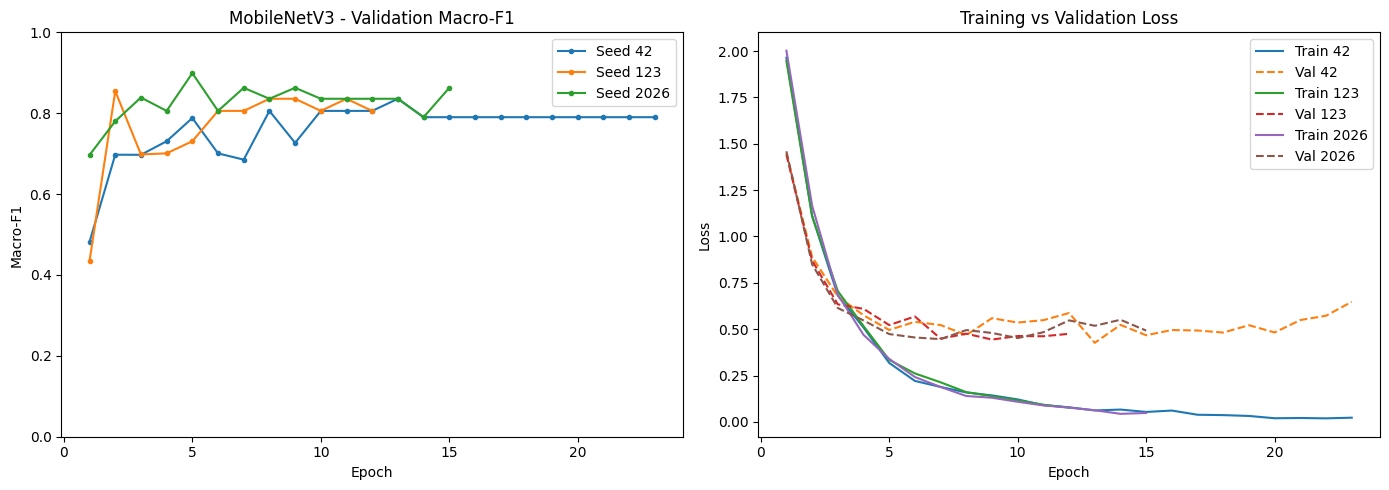

CELL 10 COMPLETED


In [14]:

import time
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.metrics import accuracy_score, f1_score

print("=" * 55)
print("CELL 10: MOBILENETV3 TEMPORAL CLASSIFIER")
print("=" * 55)

# 1. Prepare cached features
X_train_features = torch.tensor(
    np.array(train_features, dtype=np.float32),
    device=DEVICE
)

X_val_features = torch.tensor(
    np.array(val_features, dtype=np.float32),
    device=DEVICE
)

Y_train = torch.tensor(
    y[train_idx],
    dtype=torch.long,
    device=DEVICE
)

Y_val = torch.tensor(
    y[val_idx],
    dtype=torch.long,
    device=DEVICE
)

print("Train:", X_train_features.shape)
print("Validation:", X_val_features.shape)

# 2. Modern model architecture
class TemporalPoolingClassifier(nn.Module):

    def __init__(
        self,
        input_dim=576,
        num_classes=10,
        dropout=0.3
    ):
        super().__init__()

        self.classifier = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        # x: (Batch, Time, Features)
        x = torch.mean(x, dim=1)

        return self.classifier(x)


# 3. Experiment settings
MODERN_SEEDS = [42, 123, 2026]

MODERN_EPOCHS = 50
MODERN_PATIENCE = 10
MODERN_MIN_EPOCHS = 12

MODERN_LR = 0.001
MODERN_WEIGHT_DECAY = 1e-4

modern_results = []
modern_history = []

criterion_modern = nn.CrossEntropyLoss()

# 4. Validation function
@torch.inference_mode()
def evaluate_modern(model):

    model.eval()

    outputs = model(X_val_features)

    loss = criterion_modern(
        outputs, Y_val
    ).item()

    predictions = outputs.argmax(1)

    true = Y_val.cpu().numpy()
    pred = predictions.cpu().numpy()

    accuracy = accuracy_score(true, pred)

    macro_f1 = f1_score(
        true, pred,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    return loss, accuracy, macro_f1


# 5. Train with three random seeds
for seed in MODERN_SEEDS:

    print("\n" + "=" * 55)
    print(f"TRAINING MOBILENETV3 - SEED {seed}")
    print("=" * 55)

    set_seed(seed)

    modern_model = TemporalPoolingClassifier(
        input_dim=FEATURE_DIM,
        num_classes=NUM_CLASSES,
        dropout=0.3
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        modern_model.parameters(),
        lr=MODERN_LR,
        weight_decay=MODERN_WEIGHT_DECAY
    )

    best_f1 = -1.0
    best_loss = float("inf")
    best_acc = 0.0
    best_epoch = 0

    stop_reference = -1.0
    patience_counter = 0

    checkpoint_path = (
        PROJECT_DIR / "checkpoints" /
        f"mobilenet_temporal_seed_{seed}.pt"
    )

    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for epoch in range(1, MODERN_EPOCHS + 1):

        modern_model.train()

        permutation = torch.randperm(
            len(Y_train),
            device=DEVICE
        )

        running_loss = 0.0
        correct = 0
        total = 0

        for start_idx in range(
            0, len(Y_train), BATCH_SIZE
        ):

            batch_indices = permutation[
                start_idx:start_idx + BATCH_SIZE
            ]

            videos = X_train_features[
                batch_indices
            ]

            labels = Y_train[
                batch_indices
            ]

            optimizer.zero_grad(
                set_to_none=True
            )

            outputs = modern_model(videos)

            loss = criterion_modern(
                outputs, labels
            )

            loss.backward()
            optimizer.step()

            n = labels.size(0)

            running_loss += loss.item() * n

            correct += (
                outputs.argmax(1) == labels
            ).sum().item()

            total += n

        train_loss = running_loss / total
        train_acc = correct / total

        # Validation
        val_loss, val_acc, val_f1 = (
            evaluate_modern(modern_model)
        )

        modern_history.append({
            "model": "MobileNetV3_Temporal",
            "seed": seed,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1
        })

        # Save best checkpoint
        is_best = (
            val_f1 > best_f1 + 1e-8
            or (
                abs(val_f1 - best_f1) <= 1e-8
                and val_loss < best_loss
            )
        )

        if is_best:

            best_f1 = val_f1
            best_loss = val_loss
            best_acc = val_acc
            best_epoch = epoch

            torch.save({
                "model_state_dict":
                    modern_model.state_dict(),
                "seed": seed,
                "epoch": epoch,
                "val_accuracy": val_acc,
                "val_macro_f1": val_f1,
                "input_dim": FEATURE_DIM,
                "num_classes": NUM_CLASSES,
                "architecture":
                    "MobileNetV3_TemporalPooling",
                "encoder_pretrained": True,
                "encoder_frozen": True
            }, checkpoint_path)

        # Early stopping
        if val_f1 > stop_reference + 0.005:

            stop_reference = val_f1
            patience_counter = 0

        else:
            patience_counter += 1

        print(
            f"Epoch [{epoch:02d}/{MODERN_EPOCHS}] | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val F1: {val_f1:.4f} | "
            f"Patience: {patience_counter}/{MODERN_PATIENCE}",
            flush=True
        )

        if (
            epoch >= MODERN_MIN_EPOCHS
            and patience_counter >= MODERN_PATIENCE
        ):
            print(
                f"EARLY STOPPING AT EPOCH {epoch}"
            )
            break

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    training_time = (
        time.perf_counter() - start_time
    )

    # Computational cost for trainable head
    parameter_count = sum(
        p.numel()
        for p in modern_model.parameters()
    )

    model_size_mb = (
        checkpoint_path.stat().st_size /
        1024**2
    )

    peak_memory = (
        torch.cuda.max_memory_allocated() /
        1024**2
        if DEVICE.type == "cuda"
        else 0
    )

    modern_results.append({
        "model": "MobileNetV3_Temporal",
        "seed": seed,
        "epochs_run": epoch,
        "best_epoch": best_epoch,
        "val_accuracy": best_acc,
        "val_macro_f1": best_f1,
        "train_time_sec": training_time,
        "head_parameters": parameter_count,
        "head_size_mb": model_size_mb,
        "peak_gpu_memory_mb": peak_memory
    })

    # Save after every seed
    pd.DataFrame(modern_results).to_csv(
        PROJECT_DIR / "experiments" /
        "mobilenet_temporal_results.csv",
        index=False
    )

    pd.DataFrame(modern_history).to_csv(
        PROJECT_DIR / "experiments" /
        "mobilenet_temporal_history.csv",
        index=False
    )

    print(f"\nSEED {seed} COMPLETED")
    print("Epochs Run:", epoch)
    print("Best Epoch:", best_epoch)
    print("Best Accuracy:", round(best_acc, 4))
    print("Best Macro-F1:", round(best_f1, 4))

    del modern_model, optimizer

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


# 6. Final results
modern_results_df = pd.DataFrame(
    modern_results
)

modern_history_df = pd.DataFrame(
    modern_history
)

print("\n" + "=" * 55)
print("FINAL MOBILENETV3 RESULTS")
print("=" * 55)

print(
    modern_results_df.to_string(
        index=False
    )
)

print("\nMEAN AND STANDARD DEVIATION")

for metric in ["val_accuracy", "val_macro_f1"]:

    print(
        f"{metric}: "
        f"{modern_results_df[metric].mean():.4f}"
        f" +/- "
        f"{modern_results_df[metric].std():.4f}"
    )

# 7. Save best overall checkpoint
best_row = modern_results_df.loc[
    modern_results_df[
        "val_macro_f1"
    ].idxmax()
]

best_seed = int(best_row["seed"])

shutil.copy2(
    PROJECT_DIR / "checkpoints" /
    f"mobilenet_temporal_seed_{best_seed}.pt",
    PROJECT_DIR / "checkpoints" /
    "best_mobilenet_temporal.pt"
)

print("\nBest Validation Seed:", best_seed)

# 8. Learning curves
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

for seed in MODERN_SEEDS:

    h = modern_history_df[
        modern_history_df["seed"] == seed
    ]

    axes[0].plot(
        h["epoch"],
        h["val_macro_f1"],
        marker=".",
        label=f"Seed {seed}"
    )

    axes[1].plot(
        h["epoch"],
        h["train_loss"],
        label=f"Train {seed}"
    )

    axes[1].plot(
        h["epoch"],
        h["val_loss"],
        linestyle="--",
        label=f"Val {seed}"
    )

axes[0].set_title(
    "MobileNetV3 - Validation Macro-F1"
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Macro-F1")
axes[0].set_ylim(0, 1)
axes[0].legend()

axes[1].set_title(
    "Training vs Validation Loss"
)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "experiments" /
    "mobilenet_temporal_curves.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("=" * 55)
print("CELL 10 COMPLETED")


CELL 11: CNN + BiGRU + TEMPORAL ATTENTION

TRAINING ADVANCED MODEL - SEED 42
Epoch [01/50] | Train Acc: 0.4267 | Val Acc: 0.6667 | Val F1: 0.5974 | Patience: 0/10
Epoch [02/50] | Train Acc: 0.8167 | Val Acc: 0.6667 | Val F1: 0.6003 | Patience: 1/10
Epoch [03/50] | Train Acc: 0.9167 | Val Acc: 0.9000 | Val F1: 0.8990 | Patience: 0/10
Epoch [04/50] | Train Acc: 0.9500 | Val Acc: 0.8333 | Val F1: 0.8295 | Patience: 1/10
Epoch [05/50] | Train Acc: 0.9800 | Val Acc: 0.7667 | Val F1: 0.7514 | Patience: 2/10
Epoch [06/50] | Train Acc: 0.9933 | Val Acc: 0.8000 | Val F1: 0.7274 | Patience: 3/10
Epoch [07/50] | Train Acc: 0.9900 | Val Acc: 0.8333 | Val F1: 0.8362 | Patience: 4/10
Epoch [08/50] | Train Acc: 1.0000 | Val Acc: 0.8667 | Val F1: 0.8324 | Patience: 5/10
Epoch [09/50] | Train Acc: 1.0000 | Val Acc: 0.8333 | Val F1: 0.8362 | Patience: 6/10
Epoch [10/50] | Train Acc: 0.9967 | Val Acc: 0.7667 | Val F1: 0.7614 | Patience: 7/10
Epoch [11/50] | Train Acc: 1.0000 | Val Acc: 0.7667 | Val F1: 0

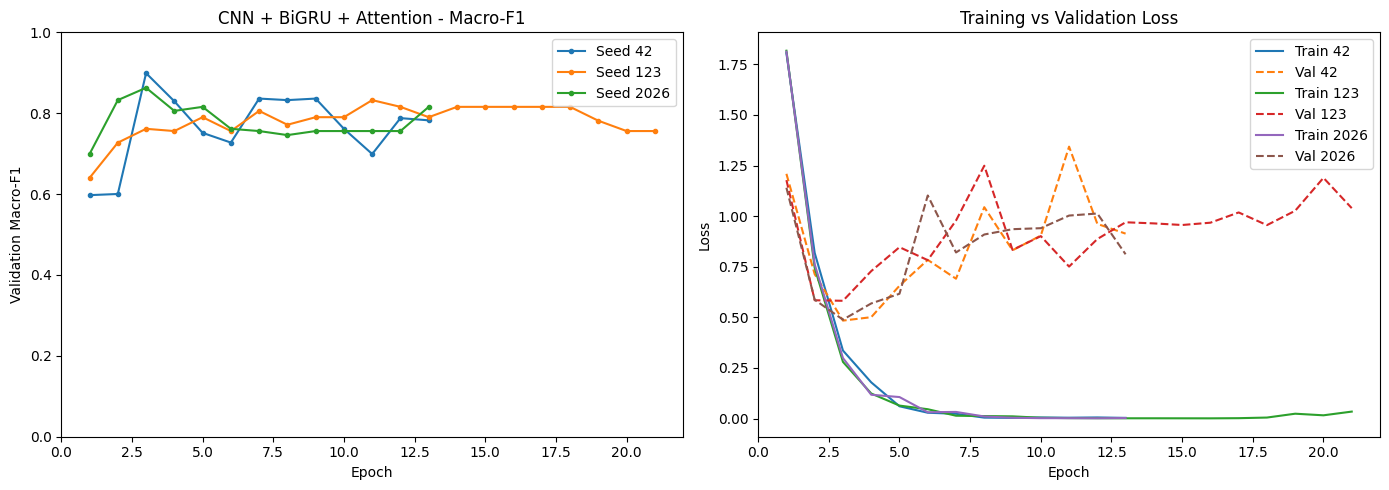


Best Validation Seed: 42
CELL 11 COMPLETED


In [15]:

import time
import shutil
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.metrics import accuracy_score, f1_score

print("=" * 55)
print("CELL 11: CNN + BiGRU + TEMPORAL ATTENTION")
print("=" * 55)

# Check required data
assert X_train_features.shape == (300, 16, 576)
assert X_val_features.shape == (30, 16, 576)

# 1. Custom Temporal Attention
class TemporalAttention(nn.Module):

    def __init__(self, input_dim, attention_dim=64):
        super().__init__()

        self.score = nn.Sequential(
            nn.Linear(input_dim, attention_dim),
            nn.Tanh(),
            nn.Linear(attention_dim, 1)
        )

    def forward(self, sequence):

        # sequence: [B, T, Features]
        scores = self.score(sequence)

        weights = torch.softmax(scores, dim=1)

        context = torch.sum(
            sequence * weights,
            dim=1
        )

        return context, weights.squeeze(-1)


# 2. Advanced Architecture
class CNNBiGRUAttention(nn.Module):

    def __init__(
        self,
        input_dim=576,
        hidden_dim=128,
        num_classes=10,
        dropout=0.3,
        with_attention=True
    ):
        super().__init__()

        self.with_attention = with_attention

        self.input_norm = nn.LayerNorm(input_dim)

        self.bigru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        temporal_dim = hidden_dim * 2

        if with_attention:
            self.attention = TemporalAttention(
                temporal_dim,
                attention_dim=64
            )
        else:
            self.attention = None

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(temporal_dim, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x, return_attention=False):

        x = self.input_norm(x)

        sequence, _ = self.bigru(x)

        if self.with_attention:
            context, weights = self.attention(sequence)
        else:
            context = sequence.mean(dim=1)
            weights = torch.full(
                (sequence.size(0), sequence.size(1)),
                1.0 / sequence.size(1),
                device=sequence.device
            )

        logits = self.classifier(context)

        if return_attention:
            return logits, weights

        return logits


# 3. Training configuration
ADV_SEEDS = [42, 123, 2026]

ADV_MAX_EPOCHS = 50
ADV_PATIENCE = 10
ADV_MIN_EPOCHS = 12
ADV_MIN_DELTA = 0.005

ADV_LR = 0.001
ADV_WEIGHT_DECAY = 1e-4

EXP_NAME = "cnn_bigru_attention"

adv_results = []
adv_history = []

loss_fn = nn.CrossEntropyLoss()


# 4. Evaluation function
@torch.inference_mode()
def evaluate_advanced(model):

    model.eval()

    logits = model(X_val_features)

    loss = loss_fn(logits, Y_val).item()

    predictions = logits.argmax(dim=1)

    y_true = Y_val.cpu().numpy()
    y_pred = predictions.cpu().numpy()

    accuracy = accuracy_score(y_true, y_pred)

    macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    return loss, accuracy, macro_f1


# 5. Train three seeds
for seed in ADV_SEEDS:

    print("\n" + "=" * 55)
    print(f"TRAINING ADVANCED MODEL - SEED {seed}")
    print("=" * 55)

    set_seed(seed)

    model = CNNBiGRUAttention(
        input_dim=FEATURE_DIM,
        hidden_dim=128,
        num_classes=NUM_CLASSES,
        dropout=0.3,
        with_attention=True
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=ADV_LR,
        weight_decay=ADV_WEIGHT_DECAY
    )

    best_f1 = -1.0
    best_loss = float("inf")
    best_acc = 0.0
    best_epoch = 0

    stop_reference = -1.0
    patience_counter = 0

    checkpoint_path = (
        PROJECT_DIR / "checkpoints" /
        f"{EXP_NAME}_seed_{seed}.pt"
    )

    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for epoch in range(1, ADV_MAX_EPOCHS + 1):

        model.train()

        permutation = torch.randperm(
            len(Y_train),
            device=DEVICE
        )

        running_loss = 0.0
        correct = 0
        total = 0

        for ids in permutation.split(BATCH_SIZE):

            features = X_train_features[ids]
            labels = Y_train[ids]

            optimizer.zero_grad(set_to_none=True)

            outputs = model(features)
            loss = loss_fn(outputs, labels)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            n = labels.size(0)

            running_loss += loss.item() * n
            correct += (
                outputs.argmax(1) == labels
            ).sum().item()
            total += n

        train_loss = running_loss / total
        train_acc = correct / total

        val_loss, val_acc, val_f1 = evaluate_advanced(
            model
        )

        adv_history.append({
            "model": EXP_NAME,
            "seed": seed,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1
        })

        # Save best validation model
        is_best = (
            val_f1 > best_f1 + 1e-8
            or (
                abs(val_f1 - best_f1) <= 1e-8
                and val_loss < best_loss
            )
        )

        if is_best:

            best_f1 = val_f1
            best_loss = val_loss
            best_acc = val_acc
            best_epoch = epoch

            torch.save({
                "model_state_dict": model.state_dict(),
                "seed": seed,
                "epoch": epoch,
                "val_accuracy": val_acc,
                "val_macro_f1": val_f1,
                "input_dim": FEATURE_DIM,
                "hidden_dim": 128,
                "num_classes": NUM_CLASSES,
                "dropout": 0.3,
                "with_attention": True
            }, checkpoint_path)

        # Early Stopping
        if val_f1 > stop_reference + ADV_MIN_DELTA:
            stop_reference = val_f1
            patience_counter = 0
        else:
            patience_counter += 1

        print(
            f"Epoch [{epoch:02d}/{ADV_MAX_EPOCHS}] | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val F1: {val_f1:.4f} | "
            f"Patience: {patience_counter}/{ADV_PATIENCE}",
            flush=True
        )

        if (
            epoch >= ADV_MIN_EPOCHS
            and patience_counter >= ADV_PATIENCE
        ):
            print(
                f"EARLY STOPPING AT EPOCH {epoch}"
            )
            break

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    training_time = time.perf_counter() - start_time

    head_parameters = sum(
        p.numel() for p in model.parameters()
    )

    encoder_parameters = sum(
        p.numel() for p in encoder.parameters()
    )

    peak_memory = (
        torch.cuda.max_memory_allocated() / 1024**2
        if DEVICE.type == "cuda"
        else 0
    )

    adv_results.append({
        "model": EXP_NAME,
        "seed": seed,
        "epochs_run": epoch,
        "best_epoch": best_epoch,
        "val_accuracy": best_acc,
        "val_macro_f1": best_f1,
        "train_time_sec": training_time,
        "head_parameters": head_parameters,
        "total_pipeline_parameters":
            head_parameters + encoder_parameters,
        "head_size_mb": (
            checkpoint_path.stat().st_size / 1024**2
        ),
        "peak_gpu_memory_mb": peak_memory
    })

    # Save after every seed
    pd.DataFrame(adv_results).to_csv(
        PROJECT_DIR / "experiments" /
        f"{EXP_NAME}_results.csv",
        index=False
    )

    pd.DataFrame(adv_history).to_csv(
        PROJECT_DIR / "experiments" /
        f"{EXP_NAME}_history.csv",
        index=False
    )

    print(f"\nSEED {seed} COMPLETED")
    print("Epochs Run:", epoch)
    print("Best Epoch:", best_epoch)
    print("Best Accuracy:", round(best_acc, 4))
    print("Best Macro-F1:", round(best_f1, 4))

    del model, optimizer

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


# 6. Final results
adv_results_df = pd.DataFrame(adv_results)
adv_history_df = pd.DataFrame(adv_history)

print("\n" + "=" * 55)
print("FINAL ADVANCED MODEL RESULTS")
print("=" * 55)

print(adv_results_df.to_string(index=False))

print("\nMEAN AND STANDARD DEVIATION")

for metric in ["val_accuracy", "val_macro_f1"]:

    print(
        f"{metric}: "
        f"{adv_results_df[metric].mean():.4f}"
        f" +/- "
        f"{adv_results_df[metric].std():.4f}"
    )

# 7. Save best checkpoint
best_row = adv_results_df.loc[
    adv_results_df["val_macro_f1"].idxmax()
]

best_seed = int(best_row["seed"])

shutil.copy2(
    PROJECT_DIR / "checkpoints" /
    f"{EXP_NAME}_seed_{best_seed}.pt",
    PROJECT_DIR / "checkpoints" /
    "best_cnn_bigru_attention.pt"
)

# 8. Save experiment configuration
config = {
    "architecture": "CNN_BiGRU_TemporalAttention",
    "encoder": "MobileNetV3-Small",
    "pretrained": True,
    "encoder_frozen": True,
    "hidden_dim": 128,
    "bidirectional": True,
    "attention": "Custom Additive Attention",
    "dropout": 0.3,
    "learning_rate": ADV_LR,
    "weight_decay": ADV_WEIGHT_DECAY,
    "max_epochs": ADV_MAX_EPOCHS,
    "patience": ADV_PATIENCE,
    "seeds": ADV_SEEDS
}

with open(
    PROJECT_DIR / "configs" /
    "advanced_model.json",
    "w"
) as f:
    json.dump(config, f, indent=2)

# 9. Learning curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for seed in ADV_SEEDS:

    h = adv_history_df[
        adv_history_df["seed"] == seed
    ]

    axes[0].plot(
        h["epoch"],
        h["val_macro_f1"],
        marker=".",
        label=f"Seed {seed}"
    )

    axes[1].plot(
        h["epoch"],
        h["train_loss"],
        label=f"Train {seed}"
    )

    axes[1].plot(
        h["epoch"],
        h["val_loss"],
        linestyle="--",
        label=f"Val {seed}"
    )

axes[0].set_title(
    "CNN + BiGRU + Attention - Macro-F1"
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation Macro-F1")
axes[0].set_ylim(0, 1)
axes[0].legend()

axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "experiments" /
    "advanced_model_curves.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("\nBest Validation Seed:", best_seed)
print("=" * 55)
print("CELL 11 COMPLETED")


CELL 12: ABLATION - WITHOUT ATTENTION

ABLATION TRAINING - SEED 42
Seed 42 | Epoch 01 | Train Acc 0.4833 | Val Acc 0.7333 | Val F1 0.7116 | Patience 0/10
Seed 42 | Epoch 02 | Train Acc 0.8333 | Val Acc 0.7667 | Val F1 0.7307 | Patience 0/10
Seed 42 | Epoch 03 | Train Acc 0.9067 | Val Acc 0.8000 | Val F1 0.7714 | Patience 0/10
Seed 42 | Epoch 04 | Train Acc 0.9567 | Val Acc 0.9000 | Val F1 0.8907 | Patience 0/10
Seed 42 | Epoch 05 | Train Acc 0.9800 | Val Acc 0.8333 | Val F1 0.8321 | Patience 1/10
Seed 42 | Epoch 06 | Train Acc 0.9900 | Val Acc 0.8333 | Val F1 0.8057 | Patience 2/10
Seed 42 | Epoch 07 | Train Acc 0.9933 | Val Acc 0.8333 | Val F1 0.8321 | Patience 3/10
Seed 42 | Epoch 08 | Train Acc 1.0000 | Val Acc 0.8667 | Val F1 0.8629 | Patience 4/10
Seed 42 | Epoch 09 | Train Acc 0.9967 | Val Acc 0.8000 | Val F1 0.7574 | Patience 5/10
Seed 42 | Epoch 10 | Train Acc 1.0000 | Val Acc 0.8667 | Val F1 0.8629 | Patience 6/10
Seed 42 | Epoch 11 | Train Acc 1.0000 | Val Acc 0.8333 | Val F1

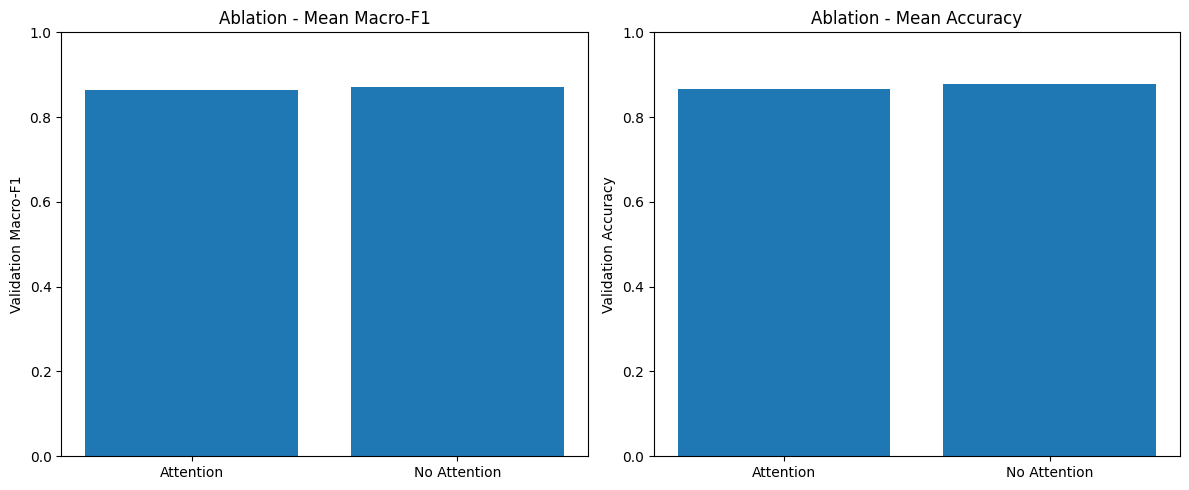

CELL 12 COMPLETED


In [16]:

import time
import shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, f1_score

print("=" * 55)
print("CELL 12: ABLATION - WITHOUT ATTENTION")
print("=" * 55)

ABLATION_NAME = "cnn_bigru_no_attention"

ABLATION_SEEDS = [42, 123, 2026]

MAX_EPOCHS = 50
PATIENCE = 10
MIN_EPOCHS = 12
MIN_DELTA = 0.005

LR = 0.001
WEIGHT_DECAY = 1e-4

abl_results = []
abl_history = []

abl_criterion = nn.CrossEntropyLoss()

# Validation function
@torch.inference_mode()
def evaluate_ablation(model):

    model.eval()

    outputs = model(X_val_features)

    loss = abl_criterion(
        outputs, Y_val
    ).item()

    pred = outputs.argmax(1).cpu().numpy()
    true = Y_val.cpu().numpy()

    acc = accuracy_score(true, pred)

    f1 = f1_score(
        true,
        pred,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    return loss, acc, f1


# Train the model without attention
for seed in ABLATION_SEEDS:

    print("\n" + "=" * 55)
    print(f"ABLATION TRAINING - SEED {seed}")
    print("=" * 55)

    set_seed(seed)

    model = CNNBiGRUAttention(
        input_dim=FEATURE_DIM,
        hidden_dim=128,
        num_classes=NUM_CLASSES,
        dropout=0.3,
        with_attention=False
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    best_f1 = -1.0
    best_loss = float("inf")
    best_acc = 0.0
    best_epoch = 0

    stop_reference = -1.0
    patience_counter = 0

    checkpoint_path = (
        PROJECT_DIR / "checkpoints" /
        f"{ABLATION_NAME}_seed_{seed}.pt"
    )

    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()

        permutation = torch.randperm(
            len(Y_train),
            device=DEVICE
        )

        running_loss = 0.0
        correct = 0
        total = 0

        for ids in permutation.split(BATCH_SIZE):

            features = X_train_features[ids]
            labels = Y_train[ids]

            optimizer.zero_grad(set_to_none=True)

            outputs = model(features)

            loss = abl_criterion(
                outputs, labels
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            n = labels.size(0)

            running_loss += loss.item() * n

            correct += (
                outputs.argmax(1) == labels
            ).sum().item()

            total += n

        train_loss = running_loss / total
        train_acc = correct / total

        val_loss, val_acc, val_f1 = (
            evaluate_ablation(model)
        )

        abl_history.append({
            "model": ABLATION_NAME,
            "seed": seed,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1
        })

        # Save best model
        is_best = (
            val_f1 > best_f1 + 1e-8
            or (
                abs(val_f1 - best_f1) <= 1e-8
                and val_loss < best_loss
            )
        )

        if is_best:

            best_f1 = val_f1
            best_loss = val_loss
            best_acc = val_acc
            best_epoch = epoch

            torch.save({
                "model_state_dict": model.state_dict(),
                "seed": seed,
                "epoch": epoch,
                "val_accuracy": val_acc,
                "val_macro_f1": val_f1,
                "input_dim": FEATURE_DIM,
                "hidden_dim": 128,
                "num_classes": NUM_CLASSES,
                "dropout": 0.3,
                "with_attention": False
            }, checkpoint_path)

        # Early stopping
        if val_f1 > stop_reference + MIN_DELTA:
            stop_reference = val_f1
            patience_counter = 0
        else:
            patience_counter += 1

        print(
            f"Seed {seed} | "
            f"Epoch {epoch:02d} | "
            f"Train Acc {train_acc:.4f} | "
            f"Val Acc {val_acc:.4f} | "
            f"Val F1 {val_f1:.4f} | "
            f"Patience {patience_counter}/{PATIENCE}",
            flush=True
        )

        if (
            epoch >= MIN_EPOCHS
            and patience_counter >= PATIENCE
        ):
            print(
                f"EARLY STOPPING AT EPOCH {epoch}"
            )
            break

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    abl_results.append({
        "model": ABLATION_NAME,
        "seed": seed,
        "epochs_run": epoch,
        "best_epoch": best_epoch,
        "val_accuracy": best_acc,
        "val_macro_f1": best_f1,
        "train_time_sec": elapsed,
        "head_parameters": sum(
            p.numel()
            for p in model.parameters()
        ),
        "model_size_mb": (
            checkpoint_path.stat().st_size / 1024**2
        )
    })

    # Save progress after every seed
    pd.DataFrame(abl_results).to_csv(
        PROJECT_DIR / "experiments" /
        f"{ABLATION_NAME}_results.csv",
        index=False
    )

    pd.DataFrame(abl_history).to_csv(
        PROJECT_DIR / "experiments" /
        f"{ABLATION_NAME}_history.csv",
        index=False
    )

    print(f"\nSEED {seed} COMPLETED")
    print("Best Epoch:", best_epoch)
    print("Best Accuracy:", round(best_acc, 4))
    print("Best Macro-F1:", round(best_f1, 4))

    del model, optimizer

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


# Final ablation results
abl_df = pd.DataFrame(abl_results)

print("\nFINAL ABLATION RESULTS")
print(abl_df.to_string(index=False))

# Load original attention results
attention_df = pd.read_csv(
    PROJECT_DIR / "experiments" /
    "cnn_bigru_attention_results.csv"
)

# Compare the same seeds
comparison = attention_df[
    ["seed", "val_accuracy", "val_macro_f1"]
].merge(
    abl_df[
        ["seed", "val_accuracy", "val_macro_f1"]
    ],
    on="seed",
    suffixes=("_attention", "_no_attention")
)

comparison["f1_difference"] = (
    comparison["val_macro_f1_attention"]
    - comparison["val_macro_f1_no_attention"]
)

comparison.to_csv(
    PROJECT_DIR / "experiments" /
    "attention_ablation_comparison.csv",
    index=False
)

print("\nATTENTION ABLATION COMPARISON")
print(comparison.to_string(index=False))

print("\nAVERAGE PERFORMANCE")
print(
    "With Attention F1:",
    round(
        comparison[
            "val_macro_f1_attention"
        ].mean(), 4
    )
)

print(
    "Without Attention F1:",
    round(
        comparison[
            "val_macro_f1_no_attention"
        ].mean(), 4
    )
)

print(
    "Mean F1 Difference:",
    round(
        comparison["f1_difference"].mean(), 4
    )
)

# Save best no-attention checkpoint
best_row = abl_df.loc[
    abl_df["val_macro_f1"].idxmax()
]

best_seed = int(best_row["seed"])

shutil.copy2(
    PROJECT_DIR / "checkpoints" /
    f"{ABLATION_NAME}_seed_{best_seed}.pt",
    PROJECT_DIR / "checkpoints" /
    "best_cnn_bigru_no_attention.pt"
)

# Plot ablation comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

labels = ["Attention", "No Attention"]

f1_means = [
    comparison["val_macro_f1_attention"].mean(),
    comparison["val_macro_f1_no_attention"].mean()
]

acc_means = [
    comparison["val_accuracy_attention"].mean(),
    comparison["val_accuracy_no_attention"].mean()
]

axes[0].bar(labels, f1_means)
axes[0].set_title("Ablation - Mean Macro-F1")
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Validation Macro-F1")

axes[1].bar(labels, acc_means)
axes[1].set_title("Ablation - Mean Accuracy")
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Validation Accuracy")

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "experiments" /
    "attention_ablation_plot.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("=" * 55)
print("CELL 12 COMPLETED")


CELL 13: PRETRAINED VS SCRATCH
Device: cuda
Selected frames: [ 0  2  4  6  8 10 12 15]
Max epochs: 15

MODE: PRETRAINED | SEED: 42
pretrained | Seed 42 | Epoch 01/15 | Train Acc 0.2367 | Val Acc 0.4333 | Val F1 0.3193 | Patience 0/5
pretrained | Seed 42 | Epoch 02/15 | Train Acc 0.4767 | Val Acc 0.7333 | Val F1 0.7000 | Patience 0/5
pretrained | Seed 42 | Epoch 03/15 | Train Acc 0.6333 | Val Acc 0.8667 | Val F1 0.8538 | Patience 0/5
pretrained | Seed 42 | Epoch 04/15 | Train Acc 0.7700 | Val Acc 0.8000 | Val F1 0.7633 | Patience 1/5
pretrained | Seed 42 | Epoch 05/15 | Train Acc 0.7733 | Val Acc 0.8667 | Val F1 0.8683 | Patience 0/5
pretrained | Seed 42 | Epoch 06/15 | Train Acc 0.8533 | Val Acc 0.8000 | Val F1 0.7633 | Patience 1/5
pretrained | Seed 42 | Epoch 07/15 | Train Acc 0.8667 | Val Acc 0.8000 | Val F1 0.7898 | Patience 2/5
pretrained | Seed 42 | Epoch 08/15 | Train Acc 0.9000 | Val Acc 0.8667 | Val F1 0.8600 | Patience 3/5
pretrained | Seed 42 | Epoch 09/15 | Train Acc 0.9233

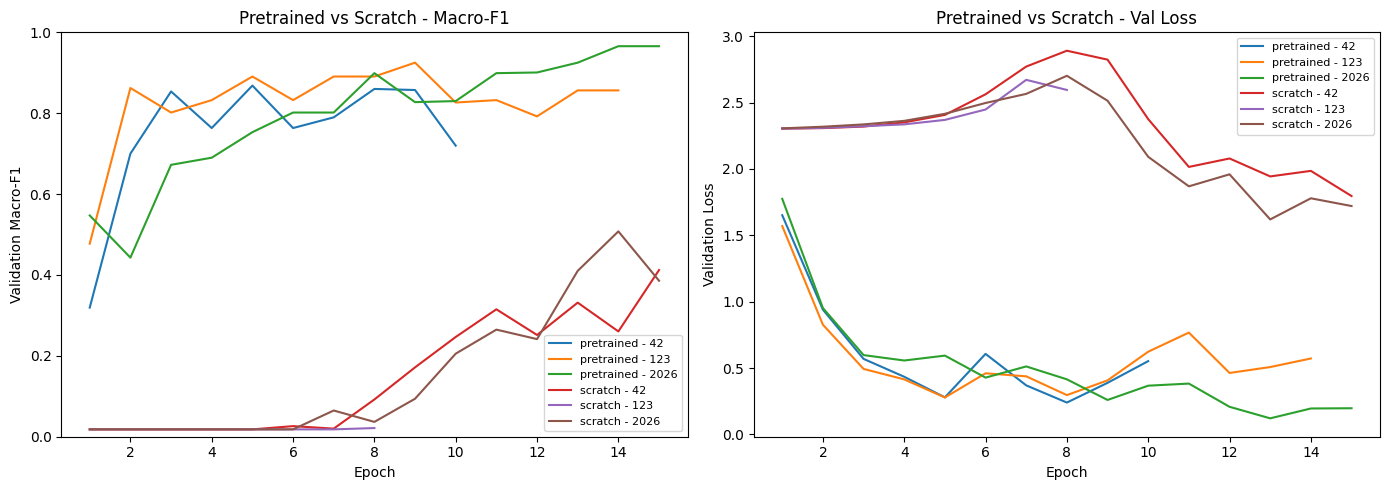

CELL 13 COMPLETED


In [17]:

# =====================================================
# CELL 13: PRETRAINED VS SCRATCH - FAIR COMPARISON
# =====================================================

import time
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from torchvision.models import (
    mobilenet_v3_small,
    MobileNet_V3_Small_Weights
)
from sklearn.metrics import accuracy_score, f1_score

print("=" * 60)
print("CELL 13: PRETRAINED VS SCRATCH")
print("=" * 60)

PROJECT_DIR = Path(PROJECT_DIR)

EXP_DIR = PROJECT_DIR / "experiments"
CKPT_DIR = PROJECT_DIR / "checkpoints"

EXP_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Configuration
COMPARE_SEEDS = [42, 123, 2026]
MODES = ["pretrained", "scratch"]

MAX_EPOCHS_13 = 15
PATIENCE_13 = 5
MIN_EPOCHS_13 = 8
MIN_DELTA_13 = 0.005

LR_13 = 3e-4
BATCH_13 = 4
FRAMES_13 = 8

USE_AMP_13 = DEVICE.type == "cuda"

FRAME_IDS = np.linspace(
    0, NUM_FRAMES - 1, FRAMES_13
).astype(int)

print("Device:", DEVICE)
print("Selected frames:", FRAME_IDS)
print("Max epochs:", MAX_EPOCHS_13)

# 2. Dataset
class VideoScratchDataset(Dataset):

    def __init__(self, indices):
        self.indices = np.asarray(
            indices, dtype=np.int64
        )

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):

        global_idx = int(self.indices[index])

        frames = np.ascontiguousarray(
            X[global_idx][FRAME_IDS]
        )

        label = int(y[global_idx])

        return (
            torch.from_numpy(frames),
            torch.tensor(label, dtype=torch.long)
        )

train_ds13 = VideoScratchDataset(train_idx)
val_ds13 = VideoScratchDataset(val_idx)

val_loader13 = DataLoader(
    val_ds13,
    batch_size=BATCH_13,
    shuffle=False,
    num_workers=0,
    pin_memory=USE_AMP_13
)

# 3. Model - same architecture for both conditions
class MobileNetVideoFull(nn.Module):

    def __init__(self, pretrained=False):
        super().__init__()

        weights = (
            MobileNet_V3_Small_Weights.IMAGENET1K_V1
            if pretrained else None
        )

        backbone = mobilenet_v3_small(
            weights=weights
        )

        self.encoder = backbone.features

        self.classifier = nn.Sequential(
            nn.Linear(576, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, NUM_CLASSES)
        )

        self.register_buffer(
            "mean",
            torch.tensor(
                [0.485, 0.456, 0.406]
            ).view(1, 3, 1, 1)
        )

        self.register_buffer(
            "std",
            torch.tensor(
                [0.229, 0.224, 0.225]
            ).view(1, 3, 1, 1)
        )

    def forward(self, videos):

        # [B, T, H, W, C]
        b, t, h, w, c = videos.shape

        frames = videos.permute(
            0, 1, 4, 2, 3
        ).reshape(
            b * t, c, h, w
        )

        frames = frames.float() / 255.0

        frames = (
            frames - self.mean
        ) / self.std

        features = self.encoder(frames)

        features = F.adaptive_avg_pool2d(
            features, 1
        ).flatten(1)

        features = features.reshape(
            b, t, -1
        )

        temporal_features = features.mean(dim=1)

        return self.classifier(temporal_features)


loss_fn13 = nn.CrossEntropyLoss()

# 4. Validation
@torch.inference_mode()
def evaluate_full13(model):

    model.eval()

    all_true = []
    all_pred = []
    total_loss = 0.0

    for videos, labels in val_loader13:

        videos = videos.to(DEVICE)
        labels = labels.to(DEVICE)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP_13
        ):
            logits = model(videos)
            loss = loss_fn13(logits, labels)

        total_loss += (
            loss.item() * labels.size(0)
        )

        all_pred.extend(
            logits.argmax(1).cpu().tolist()
        )
        all_true.extend(
            labels.cpu().tolist()
        )

    acc = accuracy_score(all_true, all_pred)

    f1 = f1_score(
        all_true,
        all_pred,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    return (
        total_loss / len(val_ds13),
        acc,
        f1
    )


# 5. Training both conditions
comparison_results13 = []
comparison_history13 = []

for mode in MODES:

    for seed in COMPARE_SEEDS:

        print("\n" + "=" * 60)
        print(f"MODE: {mode.upper()} | SEED: {seed}")
        print("=" * 60)

        set_seed(seed)

        generator = torch.Generator()
        generator.manual_seed(seed)

        train_loader13 = DataLoader(
            train_ds13,
            batch_size=BATCH_13,
            shuffle=True,
            generator=generator,
            num_workers=0,
            pin_memory=USE_AMP_13
        )

        net = MobileNetVideoFull(
            pretrained=(mode == "pretrained")
        ).to(DEVICE)

        optimizer = torch.optim.Adam(
            net.parameters(),
            lr=LR_13,
            weight_decay=1e-4
        )

        scaler = torch.amp.GradScaler(
            "cuda",
            enabled=USE_AMP_13
        )

        best_f1 = -1.0
        best_loss = float("inf")
        best_acc = 0.0
        best_epoch = 0

        stop_reference = -1.0
        patience_counter = 0

        ckpt_path = (
            CKPT_DIR /
            f"full_mobilenet_{mode}_seed_{seed}.pt"
        )

        if USE_AMP_13:
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        for epoch in range(1, MAX_EPOCHS_13 + 1):

            net.train()

            running_loss = 0.0
            correct = 0
            total = 0

            for videos, labels in train_loader13:

                videos = videos.to(DEVICE)
                labels = labels.to(DEVICE)

                optimizer.zero_grad(
                    set_to_none=True
                )

                with torch.amp.autocast(
                    device_type=DEVICE.type,
                    enabled=USE_AMP_13
                ):
                    logits = net(videos)
                    loss = loss_fn13(logits, labels)

                scaler.scale(loss).backward()

                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    net.parameters(),
                    max_norm=1.0
                )

                scaler.step(optimizer)
                scaler.update()

                n = labels.size(0)

                running_loss += loss.item() * n

                correct += (
                    logits.argmax(1) == labels
                ).sum().item()

                total += n

            train_loss = running_loss / total
            train_acc = correct / total

            val_loss, val_acc, val_f1 = (
                evaluate_full13(net)
            )

            comparison_history13.append({
                "mode": mode,
                "seed": seed,
                "epoch": epoch,
                "train_loss": train_loss,
                "train_accuracy": train_acc,
                "val_loss": val_loss,
                "val_accuracy": val_acc,
                "val_macro_f1": val_f1
            })

            is_best = (
                val_f1 > best_f1 + 1e-8
                or (
                    abs(val_f1 - best_f1) <= 1e-8
                    and val_loss < best_loss
                )
            )

            if is_best:

                best_f1 = val_f1
                best_loss = val_loss
                best_acc = val_acc
                best_epoch = epoch

                torch.save({
                    "model_state_dict":
                        net.state_dict(),
                    "mode": mode,
                    "seed": seed,
                    "epoch": epoch,
                    "val_accuracy": val_acc,
                    "val_macro_f1": val_f1,
                    "num_frames": FRAMES_13,
                    "frame_indices": FRAME_IDS.tolist(),
                    "num_classes": NUM_CLASSES
                }, ckpt_path)

            if val_f1 > stop_reference + MIN_DELTA_13:

                stop_reference = val_f1
                patience_counter = 0

            else:
                patience_counter += 1

            print(
                f"{mode} | Seed {seed} | "
                f"Epoch {epoch:02d}/{MAX_EPOCHS_13} | "
                f"Train Acc {train_acc:.4f} | "
                f"Val Acc {val_acc:.4f} | "
                f"Val F1 {val_f1:.4f} | "
                f"Patience {patience_counter}/{PATIENCE_13}",
                flush=True
            )

            if (
                epoch >= MIN_EPOCHS_13
                and patience_counter >= PATIENCE_13
            ):
                print(
                    f"EARLY STOPPING AT EPOCH {epoch}"
                )
                break

        if USE_AMP_13:
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start_time

        comparison_results13.append({
            "mode": mode,
            "seed": seed,
            "epochs_run": epoch,
            "best_epoch": best_epoch,
            "val_accuracy": best_acc,
            "val_macro_f1": best_f1,
            "train_time_sec": elapsed,
            "total_parameters": sum(
                p.numel() for p in net.parameters()
            ),
            "model_size_mb": (
                ckpt_path.stat().st_size / 1024**2
            ),
            "peak_gpu_memory_mb": (
                torch.cuda.max_memory_allocated() / 1024**2
                if USE_AMP_13 else 0.0
            )
        })

        # Save after every seed
        pd.DataFrame(comparison_results13).to_csv(
            EXP_DIR / "pretrained_vs_scratch_results.csv",
            index=False
        )

        pd.DataFrame(comparison_history13).to_csv(
            EXP_DIR / "pretrained_vs_scratch_history.csv",
            index=False
        )

        print(
            f"\nCOMPLETED: {mode} / {seed} | "
            f"Best Epoch: {best_epoch} | "
            f"Best F1: {best_f1:.4f}"
        )

        del net, optimizer, scaler
        gc.collect()

        if USE_AMP_13:
            torch.cuda.empty_cache()


# 6. Summary
results13 = pd.DataFrame(comparison_results13)
history13 = pd.DataFrame(comparison_history13)

summary13 = results13.groupby("mode").agg(
    mean_accuracy=("val_accuracy", "mean"),
    std_accuracy=("val_accuracy", "std"),
    mean_macro_f1=("val_macro_f1", "mean"),
    std_macro_f1=("val_macro_f1", "std"),
    mean_train_time=("train_time_sec", "mean")
)

print("\n" + "=" * 60)
print("FINAL PRETRAINED VS SCRATCH RESULTS")
print("=" * 60)

print(results13.to_string(index=False))

print("\nMEAN AND STANDARD DEVIATION")
print(summary13.to_string())

summary13.to_csv(
    EXP_DIR / "pretrained_vs_scratch_summary.csv"
)

# 7. Learning curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for mode in MODES:

    for seed in COMPARE_SEEDS:

        h = history13[
            (history13["mode"] == mode)
            & (history13["seed"] == seed)
        ]

        axes[0].plot(
            h["epoch"],
            h["val_macro_f1"],
            label=f"{mode} - {seed}"
        )

        axes[1].plot(
            h["epoch"],
            h["val_loss"],
            label=f"{mode} - {seed}"
        )

axes[0].set_title("Pretrained vs Scratch - Macro-F1")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation Macro-F1")
axes[0].set_ylim(0, 1)
axes[0].legend(fontsize=8)

axes[1].set_title("Pretrained vs Scratch - Val Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Loss")
axes[1].legend(fontsize=8)

plt.tight_layout()

plt.savefig(
    EXP_DIR / "pretrained_vs_scratch_curves.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("=" * 60)
print("CELL 13 COMPLETED")


CELL 14: DATA AUGMENTATION STUDY
Training videos: 300
Validation videos: 30
Augmentation: Flip + Brightness + Contrast
Validation augmentation: NONE
Test set used: NO

AUGMENTATION TRAINING - SEED 42
Seed 42 | Epoch 01/15 | Train Acc 0.2367 | Val Acc 0.5000 | Val F1 0.3860 | Patience 0/5
Seed 42 | Epoch 02/15 | Train Acc 0.4667 | Val Acc 0.7333 | Val F1 0.7207 | Patience 0/5
Seed 42 | Epoch 03/15 | Train Acc 0.5900 | Val Acc 0.7667 | Val F1 0.7281 | Patience 0/5
Seed 42 | Epoch 04/15 | Train Acc 0.7233 | Val Acc 0.8333 | Val F1 0.8221 | Patience 0/5
Seed 42 | Epoch 05/15 | Train Acc 0.7267 | Val Acc 0.9000 | Val F1 0.8981 | Patience 0/5
Seed 42 | Epoch 06/15 | Train Acc 0.8400 | Val Acc 0.7667 | Val F1 0.7271 | Patience 1/5
Seed 42 | Epoch 07/15 | Train Acc 0.8333 | Val Acc 0.8667 | Val F1 0.8464 | Patience 2/5
Seed 42 | Epoch 08/15 | Train Acc 0.8633 | Val Acc 0.8667 | Val F1 0.8564 | Patience 3/5
Seed 42 | Epoch 09/15 | Train Acc 0.8800 | Val Acc 0.8000 | Val F1 0.7524 | Patience 4/5

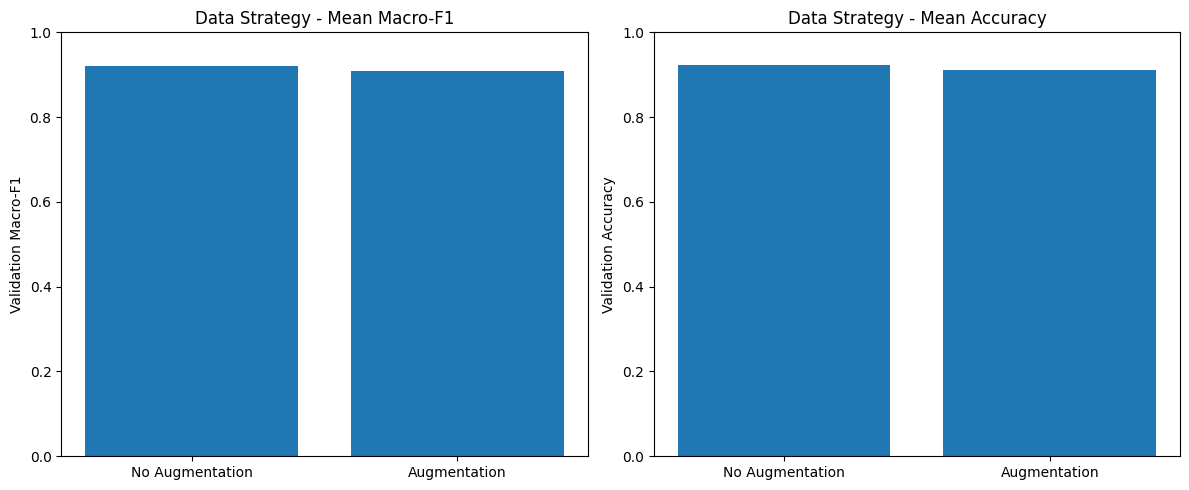

CELL 14 COMPLETED


In [18]:

# =====================================================
# CELL 14: DATA STRATEGY - AUGMENTATION STUDY
# =====================================================

import time
import gc
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch.utils.data import Dataset, DataLoader

print("=" * 60)
print("CELL 14: DATA AUGMENTATION STUDY")
print("=" * 60)

# Reuse the exact configuration from Cell 13
AUG_SEEDS = [42, 123, 2026]

AUG_RESULTS_PATH = (
    EXP_DIR / "augmentation_results.csv"
)

AUG_HISTORY_PATH = (
    EXP_DIR / "augmentation_history.csv"
)

BASE_RESULTS_PATH = (
    EXP_DIR / "pretrained_vs_scratch_results.csv"
)

assert BASE_RESULTS_PATH.exists(), (
    "Run Cell 13 first."
)

# 1. Video-level augmentation
class AugmentedVideoDataset(Dataset):

    def __init__(self, indices):
        self.indices = np.asarray(
            indices, dtype=np.int64
        )

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):

        idx = int(self.indices[index])

        frames = np.ascontiguousarray(
            X[idx][FRAME_IDS]
        ).copy()

        # Horizontal flip: consistent across all frames
        if np.random.rand() < 0.5:
            frames = frames[:, :, ::-1, :].copy()

        # Same brightness and contrast for entire clip
        brightness = np.random.uniform(0.9, 1.1)
        contrast = np.random.uniform(0.9, 1.1)

        frames = frames.astype(np.float32)

        frames = (
            (frames - 127.5) * contrast + 127.5
        ) * brightness

        frames = np.clip(
            frames, 0, 255
        ).astype(np.uint8)

        frames = np.ascontiguousarray(frames)

        return (
            torch.from_numpy(frames),
            torch.tensor(
                int(y[idx]),
                dtype=torch.long
            )
        )


aug_train_dataset = AugmentedVideoDataset(
    train_idx
)

print("Training videos:", len(aug_train_dataset))
print("Validation videos:", len(val_ds13))
print("Augmentation: Flip + Brightness + Contrast")
print("Validation augmentation: NONE")
print("Test set used: NO")

# 2. Training
aug_results = []
aug_history = []

for seed in AUG_SEEDS:

    print("\n" + "=" * 60)
    print(f"AUGMENTATION TRAINING - SEED {seed}")
    print("=" * 60)

    set_seed(seed)

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader_aug = DataLoader(
        aug_train_dataset,
        batch_size=BATCH_13,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=USE_AMP_13
    )

    # Same fully trainable pretrained model as Cell 13
    net = MobileNetVideoFull(
        pretrained=True
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        net.parameters(),
        lr=LR_13,
        weight_decay=1e-4
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP_13
    )

    best_f1 = -1.0
    best_loss = float("inf")
    best_acc = 0.0
    best_epoch = 0

    stop_reference = -1.0
    patience_counter = 0

    ckpt_path = (
        CKPT_DIR /
        f"mobilenet_augmented_seed_{seed}.pt"
    )

    if USE_AMP_13:
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS_13 + 1):

        net.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for videos, labels in train_loader_aug:

            videos = videos.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=DEVICE.type,
                enabled=USE_AMP_13
            ):
                logits = net(videos)
                loss = loss_fn13(logits, labels)

            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                net.parameters(), 1.0
            )

            scaler.step(optimizer)
            scaler.update()

            n = labels.size(0)

            running_loss += loss.item() * n

            correct += (
                logits.argmax(1) == labels
            ).sum().item()

            total += n

        train_loss = running_loss / total
        train_acc = correct / total

        # Same unaugmented validation as Cell 13
        val_loss, val_acc, val_f1 = (
            evaluate_full13(net)
        )

        aug_history.append({
            "strategy": "augmentation",
            "seed": seed,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1
        })

        is_best = (
            val_f1 > best_f1 + 1e-8
            or (
                abs(val_f1 - best_f1) <= 1e-8
                and val_loss < best_loss
            )
        )

        if is_best:

            best_f1 = val_f1
            best_loss = val_loss
            best_acc = val_acc
            best_epoch = epoch

            torch.save({
                "model_state_dict": net.state_dict(),
                "seed": seed,
                "epoch": epoch,
                "val_accuracy": val_acc,
                "val_macro_f1": val_f1,
                "num_frames": FRAMES_13,
                "num_classes": NUM_CLASSES,
                "augmentation": True,
                "architecture":
                    "MobileNetV3_FullFineTuning"
            }, ckpt_path)

        if val_f1 > stop_reference + MIN_DELTA_13:
            stop_reference = val_f1
            patience_counter = 0
        else:
            patience_counter += 1

        print(
            f"Seed {seed} | "
            f"Epoch {epoch:02d}/{MAX_EPOCHS_13} | "
            f"Train Acc {train_acc:.4f} | "
            f"Val Acc {val_acc:.4f} | "
            f"Val F1 {val_f1:.4f} | "
            f"Patience {patience_counter}/{PATIENCE_13}",
            flush=True
        )

        if (
            epoch >= MIN_EPOCHS_13
            and patience_counter >= PATIENCE_13
        ):
            print(
                f"EARLY STOPPING AT EPOCH {epoch}"
            )
            break

    if USE_AMP_13:
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    aug_results.append({
        "strategy": "augmentation",
        "seed": seed,
        "epochs_run": epoch,
        "best_epoch": best_epoch,
        "val_accuracy": best_acc,
        "val_macro_f1": best_f1,
        "train_time_sec": elapsed,
        "total_parameters": sum(
            p.numel() for p in net.parameters()
        ),
        "model_size_mb": (
            ckpt_path.stat().st_size / 1024**2
        )
    })

    # Save every seed
    pd.DataFrame(aug_results).to_csv(
        AUG_RESULTS_PATH,
        index=False
    )

    pd.DataFrame(aug_history).to_csv(
        AUG_HISTORY_PATH,
        index=False
    )

    print(f"\nSEED {seed} COMPLETED")
    print("Best Epoch:", best_epoch)
    print("Best Accuracy:", round(best_acc, 4))
    print("Best Macro-F1:", round(best_f1, 4))

    del net, optimizer, scaler
    gc.collect()

    if USE_AMP_13:
        torch.cuda.empty_cache()


# 3. Compare with Cell 13 pretrained baseline
baseline_df = pd.read_csv(
    BASE_RESULTS_PATH
)

baseline_df = baseline_df[
    baseline_df["mode"] == "pretrained"
][
    ["seed", "val_accuracy", "val_macro_f1"]
].copy()

aug_df = pd.DataFrame(aug_results)

comparison14 = baseline_df.merge(
    aug_df[
        ["seed", "val_accuracy", "val_macro_f1"]
    ],
    on="seed",
    suffixes=("_no_aug", "_aug")
)

comparison14["f1_improvement"] = (
    comparison14["val_macro_f1_aug"]
    - comparison14["val_macro_f1_no_aug"]
)

comparison14["accuracy_improvement"] = (
    comparison14["val_accuracy_aug"]
    - comparison14["val_accuracy_no_aug"]
)

comparison14.to_csv(
    EXP_DIR / "augmentation_comparison.csv",
    index=False
)

print("\n" + "=" * 60)
print("FINAL DATA AUGMENTATION COMPARISON")
print("=" * 60)

print(comparison14.to_string(index=False))

print("\nMEAN VALIDATION METRICS")

for metric in ["val_accuracy", "val_macro_f1"]:

    original = comparison14[
        f"{metric}_no_aug"
    ].mean()

    augmented = comparison14[
        f"{metric}_aug"
    ].mean()

    print(f"\n{metric}")
    print(f"Without Augmentation: {original:.4f}")
    print(f"With Augmentation:    {augmented:.4f}")
    print(f"Difference:           {augmented-original:+.4f}")


# 4. Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

labels = ["No Augmentation", "Augmentation"]

f1_means = [
    comparison14["val_macro_f1_no_aug"].mean(),
    comparison14["val_macro_f1_aug"].mean()
]

acc_means = [
    comparison14["val_accuracy_no_aug"].mean(),
    comparison14["val_accuracy_aug"].mean()
]

axes[0].bar(labels, f1_means)
axes[0].set_title("Data Strategy - Mean Macro-F1")
axes[0].set_ylabel("Validation Macro-F1")
axes[0].set_ylim(0, 1)

axes[1].bar(labels, acc_means)
axes[1].set_title("Data Strategy - Mean Accuracy")
axes[1].set_ylabel("Validation Accuracy")
axes[1].set_ylim(0, 1)

plt.tight_layout()

plt.savefig(
    EXP_DIR / "augmentation_comparison.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# 5. Save experiment config
with open(
    PROJECT_DIR / "configs" /
    "augmentation_study.json",
    "w"
) as f:
    json.dump({
        "baseline": "Full pretrained MobileNetV3",
        "augmentation": [
            "Horizontal flip p=0.5",
            "Brightness +/-10%",
            "Contrast +/-10%"
        ],
        "seeds": AUG_SEEDS,
        "num_frames": FRAMES_13,
        "max_epochs": MAX_EPOCHS_13,
        "learning_rate": LR_13,
        "validation_augmentation": False,
        "test_used": False
    }, f, indent=2)

print("=" * 60)
print("CELL 14 COMPLETED")


CELL 15: FINAL TEST EVALUATION
Selected model: MobileNetV3 Pretrained
Selected seed: 2026
Validation Macro-F1: 0.9657142857142856
Checkpoint: /content/drive/MyDrive/Video_Action_Recognition/checkpoints/full_mobilenet_pretrained_seed_2026.pt

Test videos: 75
Classes: 10
Train/Test index overlap: 0
Val/Test index overlap: 0

Model loaded successfully
Best training epoch: 14

FINAL TEST RESULTS
Test Accuracy:        0.9333
Test Precision:       0.9442
Test Recall:          0.9346
Test Macro-F1:        0.9320
Test Weighted-F1:     0.9351
Test Loss:            0.2852

Correct Predictions:  70
Wrong Predictions:    5
Total Test Videos:    75

Batch-based Inference Time: 0.695 seconds
Average Time per Video: 9.267 ms

PER-CLASS CLASSIFICATION REPORT
                precision    recall  f1-score   support

ApplyEyeMakeup     0.6667    1.0000    0.8000         6
 ApplyLipstick     1.0000    0.7500    0.8571         4
       Archery     0.8750    1.0000    0.9333         7
  BabyCrawling     1.0

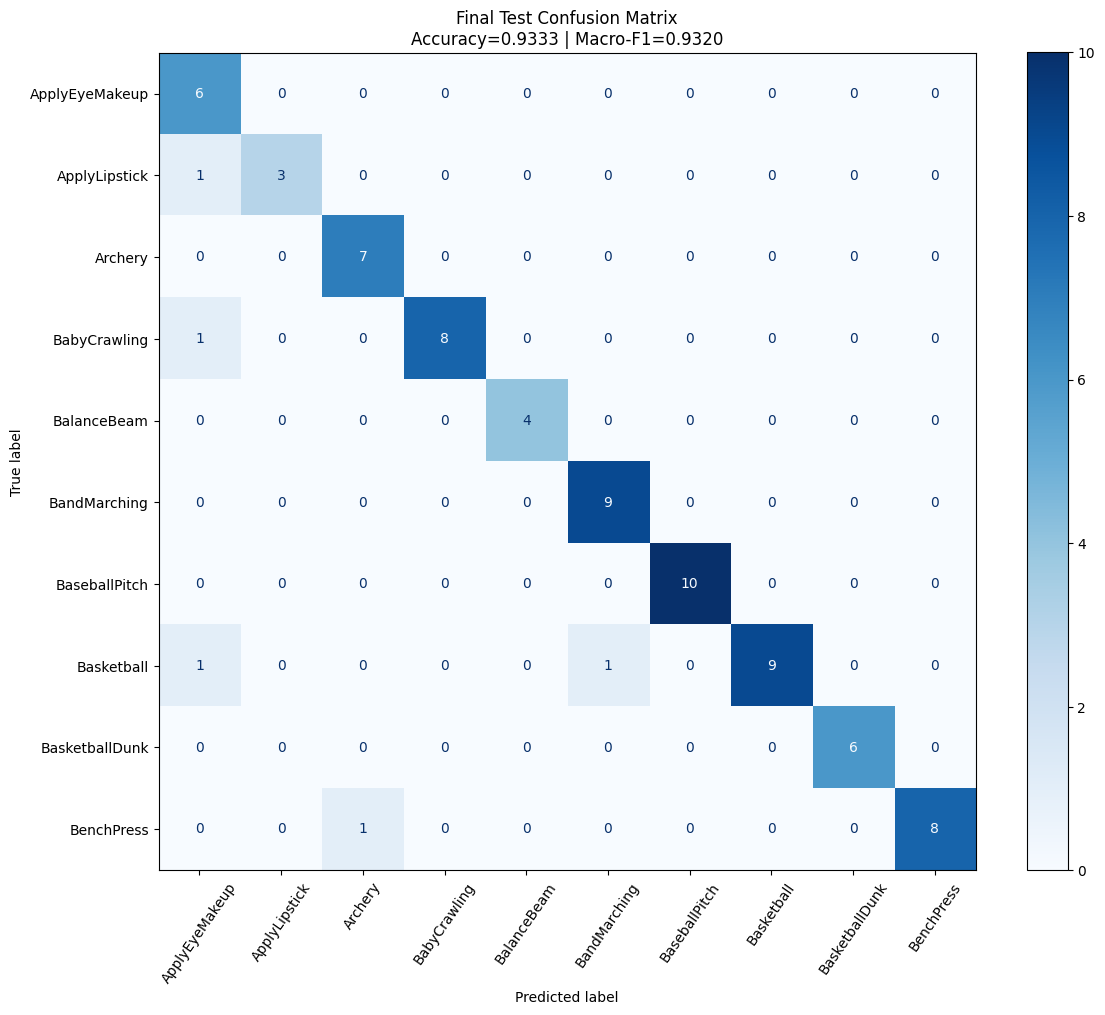


MISCLASSIFIED TEST VIDEOS
 dataset_index    true_label predicted_label  confidence  correct
           337 ApplyLipstick  ApplyEyeMakeup    0.992009    False
           348  BabyCrawling  ApplyEyeMakeup    0.968079    False
           401    BenchPress         Archery    0.804160    False
           382    Basketball    BandMarching    0.418514    False
           386    Basketball  ApplyEyeMakeup    0.305280    False


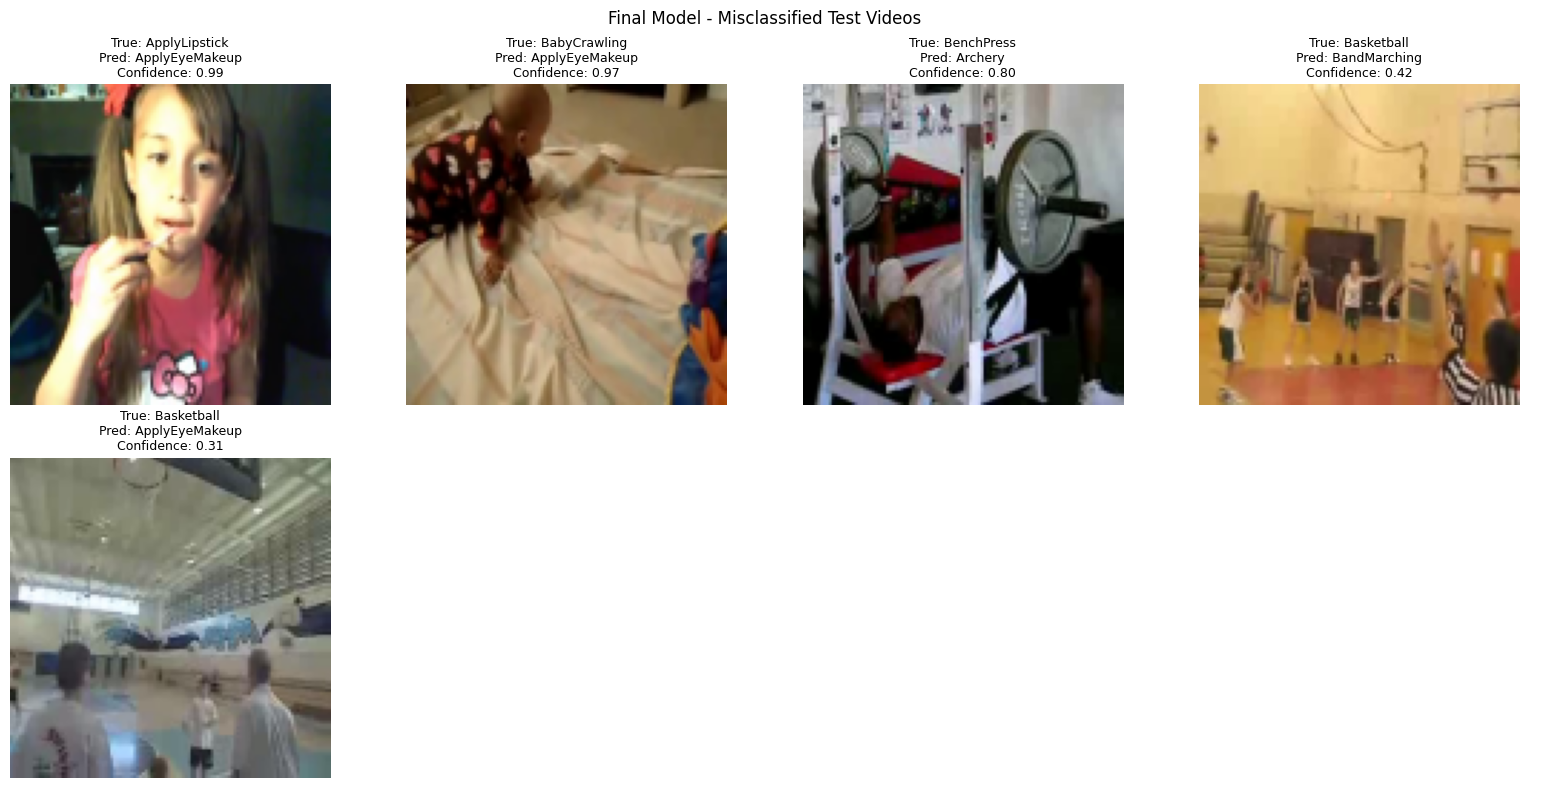


Saved final test files to: /content/drive/MyDrive/Video_Action_Recognition/experiments
CELL 15 COMPLETED


In [19]:

# =========================================================
# CELL 15: FINAL TEST EVALUATION
# =========================================================

import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("=" * 65)
print("CELL 15: FINAL TEST EVALUATION")
print("=" * 65)

# ---------------------------------------------------------
# 1. Select final model using VALIDATION results only
# ---------------------------------------------------------

val_results = pd.read_csv(
    EXP_DIR / "pretrained_vs_scratch_results.csv"
)

candidates = val_results[
    val_results["mode"] == "pretrained"
].sort_values(
    ["val_macro_f1", "val_accuracy"],
    ascending=False
)

best_row = candidates.iloc[0]
FINAL_SEED = int(best_row["seed"])

FINAL_CHECKPOINT = (
    CKPT_DIR /
    f"full_mobilenet_pretrained_seed_{FINAL_SEED}.pt"
)

assert FINAL_CHECKPOINT.exists(), (
    f"Checkpoint missing: {FINAL_CHECKPOINT}"
)

print("Selected model: MobileNetV3 Pretrained")
print("Selected seed:", FINAL_SEED)
print("Validation Macro-F1:", best_row["val_macro_f1"])
print("Checkpoint:", FINAL_CHECKPOINT)

# ---------------------------------------------------------
# 2. Verify test separation
# ---------------------------------------------------------

assert len(test_idx) == 75, (
    f"Expected 75 test videos, found {len(test_idx)}"
)

assert len(np.intersect1d(train_idx, test_idx)) == 0
assert len(np.intersect1d(val_idx, test_idx)) == 0

names15 = [str(name) for name in class_names]
assert len(names15) == NUM_CLASSES

print("\nTest videos:", len(test_idx))
print("Classes:", NUM_CLASSES)
print("Train/Test index overlap: 0")
print("Val/Test index overlap: 0")

# ---------------------------------------------------------
# 3. Load trained model
# ---------------------------------------------------------

checkpoint = torch.load(
    FINAL_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

final_model = MobileNetVideoFull(
    pretrained=False
)

final_model.load_state_dict(
    checkpoint["model_state_dict"]
)

final_model = final_model.to(DEVICE)
final_model.eval()

assert int(checkpoint["num_frames"]) == FRAMES_13

print("\nModel loaded successfully")
print("Best training epoch:", checkpoint["epoch"])

# ---------------------------------------------------------
# 4. Build untouched test loader
# ---------------------------------------------------------

test_dataset15 = VideoScratchDataset(test_idx)

test_loader15 = DataLoader(
    test_dataset15,
    batch_size=BATCH_13,
    shuffle=False,
    num_workers=0,
    pin_memory=USE_AMP_13
)

# ---------------------------------------------------------
# 5. Run test inference ONCE
# ---------------------------------------------------------

all_true = []
all_pred = []
all_conf = []

test_loss_sum = 0.0

if DEVICE.type == "cuda":
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

start_time = time.perf_counter()

with torch.inference_mode():

    for videos, labels in test_loader15:

        videos = videos.to(DEVICE)
        labels = labels.to(DEVICE)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP_13
        ):
            logits = final_model(videos)
            loss = loss_fn13(logits, labels)

        probs = torch.softmax(
            logits.float(), dim=1
        )

        confidence, predictions = probs.max(dim=1)

        all_true.extend(labels.cpu().numpy().tolist())
        all_pred.extend(
            predictions.cpu().numpy().tolist()
        )
        all_conf.extend(
            confidence.cpu().numpy().tolist()
        )

        test_loss_sum += (
            loss.item() * labels.size(0)
        )

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

total_inference_time = time.perf_counter() - start_time

all_true = np.array(all_true)
all_pred = np.array(all_pred)
all_conf = np.array(all_conf)

# ---------------------------------------------------------
# 6. Final metrics
# ---------------------------------------------------------

test_accuracy = accuracy_score(
    all_true, all_pred
)

test_precision = precision_score(
    all_true, all_pred,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    all_true, all_pred,
    average="macro",
    zero_division=0
)

test_macro_f1 = f1_score(
    all_true, all_pred,
    average="macro",
    zero_division=0
)

test_weighted_f1 = f1_score(
    all_true, all_pred,
    average="weighted",
    zero_division=0
)

test_loss = test_loss_sum / len(test_dataset15)

correct = int((all_true == all_pred).sum())
errors = len(all_true) - correct

print("\n" + "=" * 65)
print("FINAL TEST RESULTS")
print("=" * 65)

print(f"Test Accuracy:        {test_accuracy:.4f}")
print(f"Test Precision:       {test_precision:.4f}")
print(f"Test Recall:          {test_recall:.4f}")
print(f"Test Macro-F1:        {test_macro_f1:.4f}")
print(f"Test Weighted-F1:     {test_weighted_f1:.4f}")
print(f"Test Loss:            {test_loss:.4f}")

print(f"\nCorrect Predictions:  {correct}")
print(f"Wrong Predictions:    {errors}")
print(f"Total Test Videos:    {len(all_true)}")

print(
    f"\nBatch-based Inference Time: "
    f"{total_inference_time:.3f} seconds"
)
print(
    f"Average Time per Video: "
    f"{total_inference_time / len(all_true) * 1000:.3f} ms"
)

# ---------------------------------------------------------
# 7. Per-class classification report
# ---------------------------------------------------------

report_text = classification_report(
    all_true,
    all_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=names15,
    digits=4,
    zero_division=0
)

print("\n" + "=" * 65)
print("PER-CLASS CLASSIFICATION REPORT")
print("=" * 65)
print(report_text)

report_dict = classification_report(
    all_true,
    all_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=names15,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    EXP_DIR / "final_test_classification_report.csv"
)

# ---------------------------------------------------------
# 8. Confusion matrix
# ---------------------------------------------------------

cm = confusion_matrix(
    all_true,
    all_pred,
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=names15
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=55,
    values_format="d",
    colorbar=True
)

ax.set_title(
    f"Final Test Confusion Matrix\n"
    f"Accuracy={test_accuracy:.4f} | "
    f"Macro-F1={test_macro_f1:.4f}"
)

plt.tight_layout()

plt.savefig(
    EXP_DIR / "final_test_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------------------------
# 9. Predictions and error analysis
# ---------------------------------------------------------

predictions_df = pd.DataFrame({
    "dataset_index": np.asarray(test_idx),
    "true_label": [
        names15[i] for i in all_true
    ],
    "predicted_label": [
        names15[i] for i in all_pred
    ],
    "confidence": all_conf,
    "correct": all_true == all_pred
})

predictions_df.to_csv(
    EXP_DIR / "final_test_predictions.csv",
    index=False
)

wrong_df = predictions_df[
    ~predictions_df["correct"]
].sort_values(
    "confidence", ascending=False
)

print("\n" + "=" * 65)
print("MISCLASSIFIED TEST VIDEOS")
print("=" * 65)

if len(wrong_df) > 0:
    print(wrong_df.to_string(index=False))
else:
    print("No misclassified test videos!")

wrong_df.to_csv(
    EXP_DIR / "final_test_errors.csv",
    index=False
)

# ---------------------------------------------------------
# 10. Visualize misclassified examples
# ---------------------------------------------------------

num_examples = min(8, len(wrong_df))

if num_examples > 0:

    selected_errors = wrong_df.head(
        num_examples
    )

    rows = int(np.ceil(num_examples / 4))

    fig, axes = plt.subplots(
        rows, 4,
        figsize=(16, rows * 4),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, (_, row) in zip(
        axes.flat,
        selected_errors.iterrows()
    ):

        global_idx = int(row["dataset_index"])

        frame = X[
            global_idx,
            NUM_FRAMES // 2
        ]

        ax.imshow(frame)
        ax.set_title(
            f"True: {row['true_label']}\n"
            f"Pred: {row['predicted_label']}\n"
            f"Confidence: {row['confidence']:.2f}",
            fontsize=9
        )

    plt.suptitle(
        "Final Model - Misclassified Test Videos"
    )

    plt.tight_layout()

    plt.savefig(
        EXP_DIR / "final_test_errors.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()

# ---------------------------------------------------------
# 11. Save final summary
# ---------------------------------------------------------

summary15 = {
    "architecture": "MobileNetV3-Small",
    "pretraining": "ImageNet",
    "full_fine_tuning": True,
    "augmentation": False,
    "selected_seed": FINAL_SEED,
    "best_epoch": int(checkpoint["epoch"]),
    "num_test_videos": len(all_true),
    "test_accuracy": float(test_accuracy),
    "test_precision_macro": float(test_precision),
    "test_recall_macro": float(test_recall),
    "test_macro_f1": float(test_macro_f1),
    "test_weighted_f1": float(test_weighted_f1),
    "test_loss": float(test_loss),
    "correct_predictions": correct,
    "wrong_predictions": errors,
    "total_inference_time_sec": total_inference_time,
    "avg_inference_ms_per_video": (
        total_inference_time / len(all_true) * 1000
    ),
    "checkpoint": str(FINAL_CHECKPOINT)
}

with open(
    EXP_DIR / "final_test_summary.json",
    "w"
) as f:
    json.dump(summary15, f, indent=2)

print("\nSaved final test files to:", EXP_DIR)
print("=" * 65)
print("CELL 15 COMPLETED")
print("=" * 65)


In [20]:

# CELL 16A: VERIFY THE FINAL MODEL INPUT PIPELINE

import inspect
import torch

print("=" * 60)
print("FINAL MODEL INPUT VERIFICATION")
print("=" * 60)

print("\n1. Dataset preprocessing:")
print(inspect.getsource(VideoScratchDataset.__getitem__))

print("\n2. Model architecture:")
print(inspect.getsource(MobileNetVideoFull.forward))

print("\n3. Example prepared input:")
sample_video, sample_label = test_dataset15[0]

print("Video shape:", sample_video.shape)
print("Video dtype:", sample_video.dtype)
print("Minimum value:", sample_video.min().item())
print("Maximum value:", sample_video.max().item())

print("\n4. Original cached video:")
print("Original shape:", X[int(test_idx[0])].shape)

print("\n5. Final checkpoint:")
print(FINAL_CHECKPOINT)

print("=" * 60)
print("CELL 16A COMPLETED")


FINAL MODEL INPUT VERIFICATION

1. Dataset preprocessing:
    def __getitem__(self, index):

        global_idx = int(self.indices[index])

        frames = np.ascontiguousarray(
            X[global_idx][FRAME_IDS]
        )

        label = int(y[global_idx])

        return (
            torch.from_numpy(frames),
            torch.tensor(label, dtype=torch.long)
        )


2. Model architecture:
    def forward(self, videos):

        # [B, T, H, W, C]
        b, t, h, w, c = videos.shape

        frames = videos.permute(
            0, 1, 4, 2, 3
        ).reshape(
            b * t, c, h, w
        )

        frames = frames.float() / 255.0

        frames = (
            frames - self.mean
        ) / self.std

        features = self.encoder(frames)

        features = F.adaptive_avg_pool2d(
            features, 1
        ).flatten(1)

        features = features.reshape(
            b, t, -1
        )

        temporal_features = features.mean(dim=1)

        return self.clas

CELL 16B: REAL VIDEO ACTION RECOGNITION

Device: cuda
Checkpoint: /content/drive/MyDrive/Video_Action_Recognition/checkpoints/full_mobilenet_pretrained_seed_2026.pt
Final model loaded successfully!

Upload your action video (MP4 / AVI / MOV)


Saving istockphoto-2237013957-640_adpp_is.mp4 to istockphoto-2237013957-640_adpp_is.mp4

Uploaded: istockphoto-2237013957-640_adpp_is.mp4



Original extracted shape: (16, 112, 112, 3)
Model input shape: torch.Size([1, 8, 112, 112, 3])
Input dtype: torch.uint8

FINAL ACTION RECOGNITION RESULT
Predicted Action : Basketball
Confidence       : 96.41%
Inference Time   : 1.4641 sec

TOP 3 PREDICTIONS
1. Basketball: 96.41%
2. Archery: 3.33%
3. BasketballDunk: 0.12%


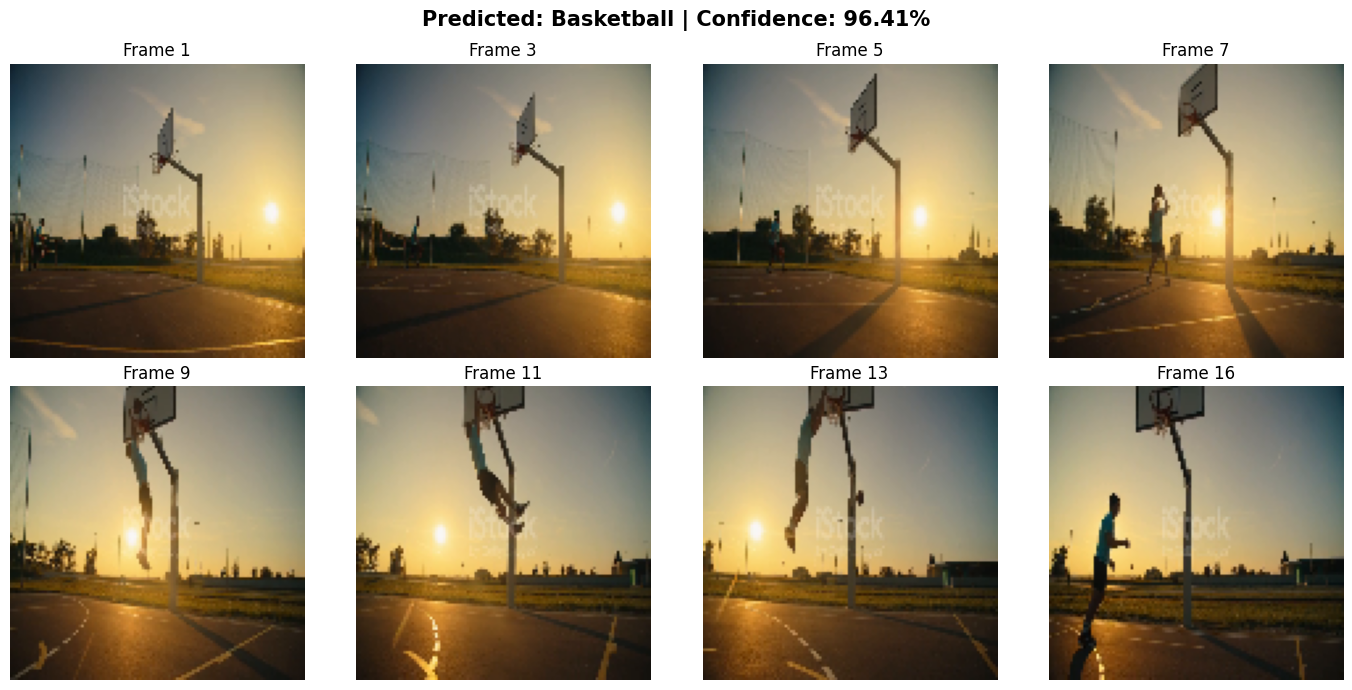


CELL 16B COMPLETED


In [21]:

# ============================================================
# CELL 16B: REAL VIDEO UPLOAD & ACTION RECOGNITION
# ============================================================

import os
import time
import inspect
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display, Video

print("=" * 65)
print("CELL 16B: REAL VIDEO ACTION RECOGNITION")
print("=" * 65)

# ------------------------------------------------------------
# 1. CLASS LABELS
# ------------------------------------------------------------

CLASS_NAMES_DEMO = [
    "ApplyEyeMakeup",
    "ApplyLipstick",
    "Archery",
    "BabyCrawling",
    "BalanceBeam",
    "BandMarching",
    "BaseballPitch",
    "Basketball",
    "BasketballDunk",
    "BenchPress"
]

# ------------------------------------------------------------
# 2. LOAD FINAL TRAINED MODEL
# ------------------------------------------------------------

device_demo = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device_demo)
print("Checkpoint:", FINAL_CHECKPOINT)

if not os.path.isfile(FINAL_CHECKPOINT):
    raise FileNotFoundError(FINAL_CHECKPOINT)

# Construct the same architecture without downloading weights.
sig = inspect.signature(MobileNetVideoFull)
model_kwargs = {}

for name, param in sig.parameters.items():
    if name in (
        "num_classes", "n_classes",
        "num_actions", "n_actions"
    ):
        model_kwargs[name] = len(CLASS_NAMES_DEMO)

    elif name in (
        "pretrained", "use_pretrained",
        "pretrained_backbone"
    ):
        model_kwargs[name] = False

    elif param.default is inspect.Parameter.empty:
        raise ValueError(
            f"Unknown required model argument: {name}"
        )

demo_model = MobileNetVideoFull(**model_kwargs)

checkpoint = torch.load(
    FINAL_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

if isinstance(checkpoint, dict):
    state = checkpoint

    for key in (
        "model_state_dict",
        "model_state",
        "state_dict",
        "best_model_state_dict",
        "best_model_state",
        "weights"
    ):
        if key in checkpoint:
            state = checkpoint[key]
            break

    demo_model.load_state_dict(state, strict=True)
else:
    raise TypeError("Unsupported checkpoint format")

demo_model = demo_model.to(device_demo)
demo_model.eval()

print("Final model loaded successfully!")

# ------------------------------------------------------------
# 3. EXTRACT 16 FRAMES FROM A NEW VIDEO
# ------------------------------------------------------------

def extract_video_frames(video_path, num_frames=16):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise ValueError("Cannot open uploaded video")

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    frames = []

    if total_frames > 0:
        indices = np.linspace(
            0, total_frames - 1, num_frames
        ).astype(int)

        for idx in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
            success, frame = cap.read()

            if not success:
                break

            frame = cv2.resize(frame, (112, 112))
            frame = cv2.cvtColor(
                frame, cv2.COLOR_BGR2RGB
            )
            frames.append(frame)

    cap.release()

    # Fallback for videos with unreliable frame metadata.
    if len(frames) != num_frames:
        frames = []
        cap = cv2.VideoCapture(video_path)

        while True:
            success, frame = cap.read()
            if not success:
                break

            frame = cv2.resize(frame, (112, 112))
            frame = cv2.cvtColor(
                frame, cv2.COLOR_BGR2RGB
            )
            frames.append(frame)

        cap.release()

        if not frames:
            raise ValueError("No readable video frames")

        indices = np.linspace(
            0, len(frames) - 1, num_frames
        ).astype(int)

        frames = [frames[i] for i in indices]

    return np.stack(frames).astype(np.uint8)

# ------------------------------------------------------------
# 4. UPLOAD VIDEO
# ------------------------------------------------------------

print("\nUpload your action video (MP4 / AVI / MOV)")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No video uploaded")

video_name = next(iter(uploaded))
video_path = os.path.abspath(video_name)

print("\nUploaded:", video_name)

display(Video(video_path, embed=True, width=480))

# ------------------------------------------------------------
# 5. PREPROCESS THE VIDEO
# ------------------------------------------------------------

video_16 = extract_video_frames(video_path)

frame_ids = np.asarray(FRAME_IDS, dtype=int)

assert len(frame_ids) == 8
assert frame_ids.min() >= 0
assert frame_ids.max() < 16

selected_frames = np.ascontiguousarray(
    video_16[frame_ids]
)

# Important: Keep uint8 and 0-255 pixel values.
# Normalization happens INSIDE the trained model.

input_tensor = torch.from_numpy(
    selected_frames
).unsqueeze(0).to(device_demo)

print("\nOriginal extracted shape:", video_16.shape)
print("Model input shape:", input_tensor.shape)
print("Input dtype:", input_tensor.dtype)

# ------------------------------------------------------------
# 6. ACTION PREDICTION
# ------------------------------------------------------------

start_time = time.perf_counter()

with torch.inference_mode():
    logits = demo_model(input_tensor)
    probabilities = torch.softmax(logits, dim=1)[0]

if device_demo.type == "cuda":
    torch.cuda.synchronize()

inference_time = time.perf_counter() - start_time

if probabilities.numel() != len(CLASS_NAMES_DEMO):
    raise ValueError("Class count does not match model")

top_probs, top_indices = torch.topk(
    probabilities, k=3
)

predicted_index = int(top_indices[0].item())
predicted_action = CLASS_NAMES_DEMO[predicted_index]
confidence = float(top_probs[0].item()) * 100

print("\n" + "=" * 65)
print("FINAL ACTION RECOGNITION RESULT")
print("=" * 65)

print(f"Predicted Action : {predicted_action}")
print(f"Confidence       : {confidence:.2f}%")
print(f"Inference Time   : {inference_time:.4f} sec")

print("\nTOP 3 PREDICTIONS")

for rank in range(3):
    class_idx = int(top_indices[rank].item())
    action = CLASS_NAMES_DEMO[class_idx]
    probability = float(top_probs[rank].item()) * 100

    print(f"{rank+1}. {action}: {probability:.2f}%")

# ------------------------------------------------------------
# 7. VISUALIZE THE 8 SELECTED FRAMES
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    ax.imshow(selected_frames[i])
    ax.set_title(f"Frame {frame_ids[i] + 1}")
    ax.axis("off")

fig.suptitle(
    f"Predicted: {predicted_action} | "
    f"Confidence: {confidence:.2f}%",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("\nCELL 16B COMPLETED")


In [22]:

%pip -q install -U "gradio>=5,<7"


In [23]:

# ============================================================
# CELL 17: INTERACTIVE VIDEO ACTION RECOGNITION DEMO
# LIVE WEBCAM + VIDEO UPLOAD
# FINAL MODEL: PRETRAINED MOBILENETV3 - SEED 2026
# ============================================================

import os
import time
import cv2
import torch
import gradio as gr
import numpy as np

from torch import nn
from torch.nn import functional as F
from torchvision.models import mobilenet_v3_small

print("=" * 60)
print("CELL 17: ACTION RECOGNITION DEMO")
print("=" * 60)

# ============================================================
# 1. CONFIGURATION
# ============================================================

CKPT_PATH = (
    "/content/drive/MyDrive/Video_Action_Recognition/"
    "checkpoints/full_mobilenet_pretrained_seed_2026.pt"
)

CLASSES = [
    "ApplyEyeMakeup",
    "ApplyLipstick",
    "Archery",
    "BabyCrawling",
    "BalanceBeam",
    "BandMarching",
    "BaseballPitch",
    "Basketball",
    "BasketballDunk",
    "BenchPress"
]

FRAME_IDS = [0, 2, 4, 6, 8, 10, 12, 15]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Number of classes:", len(CLASSES))

# ============================================================
# 2. GOOGLE DRIVE
# ============================================================

if not os.path.isfile(CKPT_PATH):
    from google.colab import drive
    drive.mount("/content/drive")

if not os.path.isfile(CKPT_PATH):
    raise FileNotFoundError(
        f"Checkpoint not found: {CKPT_PATH}"
    )

print("Checkpoint found!")

# ============================================================
# 3. FINAL MODEL ARCHITECTURE
# ============================================================

class FullMobileNetV3(nn.Module):

    def __init__(self, num_classes=10):
        super().__init__()

        self.encoder = mobilenet_v3_small(
            weights=None
        ).features

        self.classifier = nn.Sequential(
            nn.Linear(576, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

        self.register_buffer(
            "mean",
            torch.tensor(
                [0.485, 0.456, 0.406]
            ).view(1, 3, 1, 1)
        )

        self.register_buffer(
            "std",
            torch.tensor(
                [0.229, 0.224, 0.225]
            ).view(1, 3, 1, 1)
        )

    def forward(self, videos):

        # Input: [B, T, H, W, C]

        b, t, h, w, c = videos.shape

        frames = videos.permute(
            0, 1, 4, 2, 3
        ).reshape(
            b * t, c, h, w
        )

        frames = frames.float() / 255.0

        frames = (
            frames - self.mean
        ) / self.std

        features = self.encoder(frames)

        features = F.adaptive_avg_pool2d(
            features, 1
        ).flatten(1)

        features = features.reshape(
            b, t, -1
        )

        temporal_features = features.mean(dim=1)

        output = self.classifier(
            temporal_features
        )

        return output

# ============================================================
# 4. LOAD TRAINED CHECKPOINT
# ============================================================

checkpoint = torch.load(
    CKPT_PATH,
    map_location="cpu",
    weights_only=True
)

def find_state_dict(obj):

    if isinstance(obj, dict):

        for key in [
            "model_state_dict",
            "state_dict",
            "model_state",
            "model",
            "weights"
        ]:
            value = obj.get(key)

            if (
                isinstance(value, dict)
                and any(
                    isinstance(v, torch.Tensor)
                    for v in value.values()
                )
            ):
                return value

        if any(
            isinstance(v, torch.Tensor)
            for v in obj.values()
        ):
            return obj

    raise ValueError(
        "No model state_dict found in checkpoint."
    )


state_dict = find_state_dict(checkpoint)

state_dict = {
    k.removeprefix("module.").removeprefix(
        "_orig_mod."
    ): v
    for k, v in state_dict.items()
}

model = FullMobileNetV3(
    num_classes=len(CLASSES)
)

missing, unexpected = model.load_state_dict(
    state_dict,
    strict=False
)

critical_missing = [
    k for k in missing
    if k not in ("mean", "std")
]

if critical_missing or unexpected:
    raise RuntimeError(
        "Checkpoint architecture mismatch!\n"
        f"Missing: {critical_missing[:10]}\n"
        f"Unexpected: {unexpected[:10]}"
    )

model = model.to(DEVICE)
model.eval()

print("Final trained model loaded successfully!")
print(
    "Parameters:",
    sum(p.numel() for p in model.parameters())
)

# ============================================================
# 5. FRAME PREPROCESSING
# ============================================================

def process_frame(frame):

    if frame is None:
        raise ValueError("Empty frame!")

    frame = np.asarray(frame)

    if frame.ndim == 2:
        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_GRAY2RGB
        )

    if frame.shape[-1] == 4:
        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_RGBA2RGB
        )

    frame = cv2.resize(
        frame,
        (112, 112),
        interpolation=cv2.INTER_AREA
    )

    return frame.astype(np.uint8)

# ============================================================
# 6. MODEL INFERENCE
# ============================================================

def predict_frames(frames):

    selected_frames = np.stack(
        [frames[i] for i in FRAME_IDS],
        axis=0
    )

    tensor = torch.from_numpy(
        selected_frames
    ).unsqueeze(0).to(DEVICE)

    start = time.perf_counter()

    with torch.inference_mode():

        logits = model(tensor)

        probabilities = torch.softmax(
            logits, dim=1
        )[0].cpu().numpy()

    inference_time = (
        time.perf_counter() - start
    ) * 1000

    predicted_index = int(
        np.argmax(probabilities)
    )

    predicted_class = CLASSES[predicted_index]

    confidence = float(
        probabilities[predicted_index]
    )

    scores = {
        CLASSES[i]: float(probabilities[i])
        for i in range(len(CLASSES))
    }

    result = (
        f"### Predicted Action: {predicted_class}\n"
        f"### Confidence: {confidence * 100:.2f}%"
    )

    return result, scores, inference_time

# ============================================================
# 7. VIDEO FILE PROCESSING
# ============================================================

def extract_video_frames(video_path):

    if isinstance(video_path, tuple):
        video_path = video_path[0]

    if not video_path:
        raise gr.Error(
            "Please upload or record a video."
        )

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise gr.Error(
            "Cannot open video file!"
        )

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    frames = []

    try:

        if total_frames > 0:

            positions = np.linspace(
                0,
                total_frames - 1,
                16
            ).astype(int)

            for position in positions:

                cap.set(
                    cv2.CAP_PROP_POS_FRAMES,
                    int(position)
                )

                success, frame = cap.read()

                if not success:
                    raise gr.Error(
                        "Could not read video frames."
                    )

                rgb = cv2.cvtColor(
                    frame,
                    cv2.COLOR_BGR2RGB
                )

                frames.append(
                    process_frame(rgb)
                )

        else:

            all_frames = []

            while True:

                success, frame = cap.read()

                if not success:
                    break

                rgb = cv2.cvtColor(
                    frame,
                    cv2.COLOR_BGR2RGB
                )

                all_frames.append(
                    process_frame(rgb)
                )

            if not all_frames:
                raise gr.Error(
                    "No valid frames found!"
                )

            positions = np.linspace(
                0,
                len(all_frames) - 1,
                16
            ).astype(int)

            frames = [
                all_frames[i]
                for i in positions
            ]

    finally:
        cap.release()

    return frames

# ============================================================
# 8. UPLOADED VIDEO PREDICTION
# ============================================================

def predict_video(video_path):

    frames = extract_video_frames(video_path)

    result, scores, inference_time = (
        predict_frames(frames)
    )

    info = (
        "Original sampled frames: 16\n"
        "Model input frames: 8\n"
        "Resolution: 112x112\n"
        f"Inference Time: {inference_time:.2f} ms"
    )

    return result, scores, info

# ============================================================
# 9. LIVE WEBCAM PROCESSING
# ============================================================

def webcam_predict(frame, state):

    if not state:
        state = {
            "frames": [],
            "count": 0,
            "result": "Waiting...",
            "scores": {}
        }

    if frame is None:
        return (
            state["result"],
            state["scores"],
            "Waiting for camera...",
            state
        )

    processed = process_frame(frame)

    state["frames"].append(processed)

    state["frames"] = state["frames"][-16:]

    state["count"] += 1

    collected = len(state["frames"])

    if collected < 16:

        status = (
            f"Collecting Frames: {collected}/16"
        )

        return (
            "### Collecting video frames...",
            {},
            status,
            state
        )

    # Update prediction every 4 incoming frames

    if (state["count"] - 16) % 4 == 0:

        result, scores, inference_time = (
            predict_frames(state["frames"])
        )

        state["result"] = result
        state["scores"] = scores
        state["inference_time"] = inference_time

    status = (
        "LIVE CAMERA ACTIVE\n"
        "Frames used: 16 -> 8\n"
        f"Prediction Time: "
        f"{state.get('inference_time', 0):.2f} ms"
    )

    return (
        state["result"],
        state["scores"],
        status,
        state
    )

# ============================================================
# 10. RESET CAMERA
# ============================================================

def reset_camera():

    new_state = {
        "frames": [],
        "count": 0,
        "result": "### Waiting...",
        "scores": {}
    }

    return (
        new_state,
        "### Waiting...",
        {},
        "Camera reset successfully."
    )

# ============================================================
# 11. GRADIO USER INTERFACE
# ============================================================

with gr.Blocks(
    title="AI Video Action Recognition"
) as demo:

    gr.Markdown(
        """
        # AI VIDEO ACTION RECOGNITION

        ### Deep Learning Final Project

        **Model:** Pretrained MobileNetV3

        **Classes:** 10

        **Input:** 8 RGB Frames (112x112)

        **Test Accuracy:** 93.33%

        ---
        """
    )

    with gr.Tabs():

        # ----------------------------------------------------
        # LIVE WEBCAM TAB
        # ----------------------------------------------------

        with gr.Tab("LIVE WEBCAM"):

            gr.Markdown(
                "### Start your laptop camera"
            )

            gr.Markdown(
                "The system analyzes incoming camera "
                "frames and continuously updates "
                "its prediction."
            )

            webcam = gr.Image(
                label="Laptop Camera",
                sources=["webcam"],
                type="numpy",
                streaming=True,
                height=360
            )

            camera_state = gr.State({
                "frames": [],
                "count": 0,
                "result": "### Waiting...",
                "scores": {}
            })

            with gr.Row():

                live_result = gr.Markdown(
                    "### Waiting for camera..."
                )

                live_scores = gr.Label(
                    label="Top 3 Predictions",
                    num_top_classes=3
                )

            live_status = gr.Textbox(
                label="Camera Status",
                interactive=False
            )

            reset_button = gr.Button(
                "Reset Camera Predictions"
            )

            webcam.stream(
                fn=webcam_predict,
                inputs=[
                    webcam,
                    camera_state
                ],
                outputs=[
                    live_result,
                    live_scores,
                    live_status,
                    camera_state
                ],
                stream_every=0.4,
                time_limit=180,
                concurrency_limit=1
            )

            reset_button.click(
                fn=reset_camera,
                inputs=[],
                outputs=[
                    camera_state,
                    live_result,
                    live_scores,
                    live_status
                ]
            )

        # ----------------------------------------------------
        # VIDEO UPLOAD TAB
        # ----------------------------------------------------

        with gr.Tab("UPLOAD VIDEO"):

            gr.Markdown(
                "### Upload or record a video"
            )

            video_input = gr.Video(
                label="Select Video",
                sources=[
                    "upload",
                    "webcam"
                ],
                format="mp4"
            )

            predict_button = gr.Button(
                "PREDICT ACTION",
                variant="primary"
            )

            with gr.Row():

                video_result = gr.Markdown(
                    "### Upload a video to start."
                )

                video_scores = gr.Label(
                    label="Top 3 Predictions",
                    num_top_classes=3
                )

            video_status = gr.Textbox(
                label="Inference Information",
                interactive=False
            )

            predict_button.click(
                fn=predict_video,
                inputs=[video_input],
                outputs=[
                    video_result,
                    video_scores,
                    video_status
                ]
            )

    gr.Markdown(
        """
        ---

        **Video Action Recognition — Final Project**

        Pretrained MobileNetV3 | PyTorch | Gradio

        Note: Confidence is not a guarantee
        of prediction correctness.
        """
    )

# ============================================================
# 12. LAUNCH DEMO
# ============================================================

print("=" * 60)
print("STARTING GRADIO INTERFACE...")
print("=" * 60)

demo.queue().launch(
    share=True,
    inline=False,
    show_error=True
)


CELL 17: ACTION RECOGNITION DEMO
Device: cuda
Number of classes: 10
Checkpoint found!
Final trained model loaded successfully!
Parameters: 1002154
STARTING GRADIO INTERFACE...
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d0ccd70e9848ca377b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
